# Racism detection in tweets with BERT-large, CNN and BiLSTM, and a hybrid text-and-features model

This is the code from my dissertation for the MSc in Big Data Analytics and Artificial Intelligence (Letterkenny Institute of Technology, now part of ATU, 2021), corrected and brought up to date in 2026. It keeps the 2021 design: the same BERT-large model and preprocessor from TensorFlow Hub, CNN and BiLSTM layers on top, and a second branch of numeric features fused with the text: in current terms a multimodal model, combining text with tabular features. Every step of the 2021 notebook (kept unchanged in `original/`) is still here, in the same order, as a working example to reuse for other text-classification problems.

In brief: fixing the 2021 wiring takes the text model from a test PR-AUC (a score from 0 to 1 for how well a model finds the racist tweets; section 6) of 0.30 to 0.79, and tuning two of its settings takes it to 0.81. The hybrid that fuses the two branches' hidden layers then scores highest, 0.82, consistent with the dissertation's hypothesis that the numeric branch adds to the text; but this test set cannot tell it, the other corrected models and a word-count baseline apart, because this dataset's racist class, nine authors writing mostly about Islam, sets a ceiling; and the corrected models miss most racism aimed at other groups, a case of shortcut learning (section 9). Each section ends with the 2021 steps it covers and what changed; the pitfalls section at the end collects the checks worth reusing in any project.

> **Content warning.** The data contains racist and abusive language. Printed examples mask slurs; the models train on the original text.

## 1. Setup

TensorFlow Hub's BERT layers are written for Keras 2, while TensorFlow 2.16 and later use Keras 3 by default. Setting `TF_USE_LEGACY_KERAS` **before** TensorFlow is imported makes `tf.keras` the Keras 2 package (`tf-keras`), which is what this code assumes.

Under WSL, TensorFlow's default GPU memory allocator stops at about 1.5 GB, short of what BERT-large needs; `TF_GPU_ALLOCATOR=cuda_malloc_async` hands memory management to CUDA itself. TensorFlow 2.21 installed with pip also has a packaging bug: it cannot find one of NVIDIA's libraries (cuSOLVER) and quietly runs on the CPU, about 50 times slower for BERT. The next cell loads that library first, so the GPU is used on any Linux machine with an NVIDIA GPU, however Jupyter was started. A fixed seed makes every run pick the same splits and start from the same weights. That is not enough on a GPU, which adds numbers up in whatever order its threads finish, so training drifts slightly from run to run; this notebook's results moved by as much as 0.02 between two runs. *Op determinism* makes the GPU use a fixed order, so a rerun reproduces every number. It costs time: an epoch of the corrected model or the hybrids takes about half as long again, a few minutes over the whole notebook. Two settings only change what is printed: TensorFlow's information messages are hidden, and tables show text in full.

In [1]:
import ctypes
import glob
import os
import site
import sys
from pathlib import Path

import numpy as np
import pandas as pd

os.environ["TF_USE_LEGACY_KERAS"] = "1"  # these three must be set before TensorFlow is imported
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"  # the default allocator stops at 1.5 GB under WSL
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"  # hide TensorFlow's information messages; warnings and errors still show

# TensorFlow 2.21's pip build leaves nvidia/cusolver out of its library search path and silently falls back
# to the CPU; loading cuSOLVER by full path first fixes that, and does nothing where pip installed no NVIDIA libraries.
for library in glob.glob(f"{site.getsitepackages()[0]}/nvidia/cusolver/lib/libcusolver.so.*"):
    ctypes.CDLL(library, mode=ctypes.RTLD_GLOBAL)

import tensorflow as tf  # noqa: E402 (must follow the two steps above)

pd.set_option("display.max_colwidth", None)  # show text in full: several tables exist to show what was done to it

SEED = 42
tf.keras.utils.set_random_seed(SEED)  # seeds Python, NumPy and TensorFlow together
tf.config.experimental.enable_op_determinism()  # the GPU sums in a fixed order, so reruns reproduce every number

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)  # take GPU memory as needed, not all of it up front
print(f"python {sys.version.split()[0]} | tensorflow {tf.__version__} | pandas {pd.__version__} | "
      f"GPU: {gpus[0].name if gpus else 'none (BERT will run about 50 times slower)'}")

python 3.12.3 | tensorflow 2.21.0 | pandas 3.0.6 | GPU: /physical_device:GPU:0


### The 2021 setup, revisited

| 2021 step | What it did | What the rebuild found | Now |
|---|---|---|---|
| `!pip install` inside the notebook, no versions | installed whatever was newest that day | releases since then broke the code (Keras 3, pandas 2, setuptools 82) | versions pinned in `uv.lock`, installed once with `uv sync` |
| `from keras.callbacks import ...` beside `tf.keras` | two Keras packages in one model | standalone Keras and `tf.keras` objects stop mixing once their versions diverge | everything through `tf.keras` (Keras 2, from `tf-keras`) |
| `from tensorflow.python.keras import regularizers` | L2 penalties for the CNN | `tensorflow.python` is TensorFlow's private code, which later releases moved | the public `keras.regularizers` |
| `from official.nlp import optimization` | AdamW, from TensorFlow's BERT tutorial | imported, never used | not needed: the 2021 model trained with plain Adam |
| nltk stop words and wordnet; chart_studio | stop words, word roots, interactive charts | downloaded or installed, never used (the stop words came from scikit-learn) | not needed |
| dataprep `clean_country` | standardised user locations | dataprep no longer installs beside current Python and pandas, and the location field cannot be recovered (section 2) | the technique shown in section 5, with `country_converter` |
| `sys.setrecursionlimit(22000)` | raised Python's recursion limit | no step in the notebook was found to need it | not needed |
| no seed | | every run split and trained differently | one seed, and op determinism |

## 2. Data: finding and combining the available datasets

The 2021 plan was to gather every available racism dataset and build the best-labelled set from them, in three steps:

1. Two Kaggle files held tweet text and looked like two labellings of the same tweets, so they were **merged** on the text: a tweet found in both files has been labelled twice.
2. Waseem's expert and amateur annotations came as tweet IDs. The most trusted labels were kept (the expert's, or the amateurs' when all agreed), and each tweet's text and metadata were downloaded from Twitter with the Hydrator app.
3. Those tweets were **stacked** onto the merged table, and repeated texts removed.

This notebook follows the same plan and adjusts one step, where the files turn out to differ from what they seemed.

| File in `data/` | Source | What it holds |
|---|---|---|
| `twitter_racism_parsed_dataset.csv` | [Kaggle: racism-tweets](https://www.kaggle.com/datasets/raghadabdullah/racism-tweets) | tweet text labelled `racism` or `none` |
| `classified_tweets.csv` | [Kaggle: classified-tweets](https://www.kaggle.com/datasets/munkialbright/classified-tweets) | tweet text and four undocumented label columns |
| `NAACL_SRW_2016.csv`, `NLP+CSS_2016.csv` | [Waseem & Hovy's annotations](https://github.com/zeeraktalat/hatespeech) | tweet IDs and labels only |

The Hydrator route is closed now. Twitter's free API ended in 2023, and when this notebook was rebuilt, none of 50 sampled racism tweets could still be viewed: 48 were refused, the response for suspended or protected accounts, and 2 had been deleted, while 28 of 50 sampled non-racist tweets were still online, so the check itself worked. The Hydrator returned 35 fields with every tweet, from the author's follower and following counts, name, description and location to the tweet's likes, retweets and hashtags. The 2021 model used the follower and following counts beside each tweet's sentiment, and the notebook explored the locations. None of that can be recovered, so this notebook works from the text.

In [2]:
DATA = "data" if Path("data").is_dir() else "https://raw.githubusercontent.com/JoshPola96/dissertation-racism-detection-bert-cnn-bilstm/main/data"

racism_tweets = pd.read_csv(f"{DATA}/twitter_racism_parsed_dataset.csv", dtype={"id": str})
print(f"{len(racism_tweets):,} rows | {racism_tweets['id'].nunique()} distinct ids, e.g. {racism_tweets['id'].iloc[0]}")

13,471 rows | 167 distinct ids, e.g. 5.77E+17


Only 167 distinct IDs across 13,471 rows: the file was saved through Excel, which turned 18-digit tweet IDs into numbers like `5.77E+17`. The IDs can no longer identify tweets, so they go, along with two columns that repeat the label. (Store IDs as text, never as numbers.) One row's text is `#NULL!`, an Excel error value saved as if it were a tweet.

In [3]:
file1 = (racism_tweets.drop(columns=["index", "oh_label", "id"])
         .rename(columns={"Text": "text", "Annotation": "annotation"}))
file1 = file1[file1["text"].str.strip() != "#NULL!"]
print(f"{len(file1):,} tweets |", file1["annotation"].value_counts().to_dict())

13,470 tweets | {'none': 11500, 'racism': 1970}


### File 2: what do its labels mean?

The second file has four label columns and no documentation. The 2021 notebook assumed `cyberbullying = 1` means racism. The tweets themselves can test that: how often does each label value mention race or religion, and how often does it carry `#mkr`, the TV-show hashtag that fills Waseem & Hovy's sexism class?

In [4]:
classified = pd.read_csv(f"{DATA}/classified_tweets.csv")
race_terms = r"\b(?:race|racis|black|white|muslim|islam|jew|asian|mexican|immigra)"
classified.groupby("cyberbullying")["text"].agg(
    tweets="size",
    race_or_religion_terms=lambda text: text.str.contains(race_terms, case=False).mean(),
    mkr_hashtag=lambda text: text.str.contains("#mkr", case=False).mean(),
).round(2)

,tweets,race_or_religion_terms,mkr_hashtag
cyberbullying,,,
0,17256,0.03,0.12
1,945,0.64,0.01
2,1733,0.02,0.23


Value 1 is the racism class: most of its tweets mention race or religion, against a few per cent for the other values. Value 2 is the sexism class (`#mkr`). So keep 0 (`none`) and 1 (`racism`), as the 2021 notebook did.

In [5]:
file2 = (classified.loc[classified["cyberbullying"].isin([0, 1]), ["text", "cyberbullying"]]
         .rename(columns={"cyberbullying": "annotation"}))
file2["annotation"] = file2["annotation"].map({0: "none", 1: "racism"})
print(f"{len(file2):,} tweets |", file2["annotation"].value_counts().to_dict())

18,201 tweets | {'none': 17256, 'racism': 945}


### Combining the two files

The 2021 notebook merged the two files on their text. A merge keeps only texts present in **both** files, which suits two labellings of the same tweets: every tweet kept has been labelled twice, and the two labels can be compared. The next cell tests whether the files really hold the same tweets.

In [6]:
merged = pd.merge(file1, file2, on="text").drop_duplicates("text")
stacked = pd.concat([file1, file2]).drop_duplicates("text")
agree = merged["annotation_x"] == merged["annotation_y"]
print(f"tweets in both files: {len(merged):,} of {len(stacked):,} distinct | racist tweets among them: "
      f"{merged['annotation_x'].eq('racism').sum():,} of {file1['annotation'].eq('racism').sum():,} | "
      f"labels agree on {agree.mean():.1%} of the shared tweets ({(~agree).sum()} disagree)")

tweets in both files: 6,723 of 23,260 distinct | racist tweets among them: 982 of 1,970 | labels agree on 99.4% of the shared tweets (41 disagree)


Where the files overlap, their labels almost always agree, so the merge does what it was meant to do. But they overlap far less than expected: the merge keeps under a third of the tweets and half of the racist ones. So this notebook keeps the agreement check in another form: it stacks the two files and drops only the texts the files label differently.

In [7]:
tweets = pd.concat([file1, file2], ignore_index=True)
tweets = tweets[tweets.groupby("text")["annotation"].transform("nunique") == 1].drop_duplicates("text")

In [8]:
print(f"{len(tweets):,} tweets |", tweets["annotation"].value_counts().to_dict())
assert tweets["text"].is_unique, "some text appears more than once"
assert set(tweets["annotation"]) == {"none", "racism"}, "unexpected labels"

23,219 tweets | {'none': 21286, 'racism': 1933}


### Where both files come from

File 1's racism count matches Waseem & Hovy's published racism labels exactly (next cell), and file 2 adds almost no racism tweets that file 1 lacks. So the racism class of both files comes from one study: Waseem & Hovy (2016), whose paper describes it as "1,972 for racist content sent by 9 users", and one of those accounts wrote most of them: 96% by Arango et al.'s (2019) count, 99% by Wiegand et al.'s (2019). A model trained on it can learn to recognise nine accounts' writing rather than racism itself. Keep that in mind when reading every result in this notebook.

In [9]:
naacl = pd.read_csv(f"{DATA}/NAACL_SRW_2016.csv", header=None, names=["id", "label"], dtype=str)
new_racist = set(file2.loc[file2["annotation"] == "racism", "text"]) - set(file1["text"])
print("Waseem & Hovy (2016) labels:", naacl["label"].value_counts().to_dict())
print(f"racism tweets in file 1: {(file1['annotation'] == 'racism').sum():,} | new ones in file 2: {len(new_racist)}")

Waseem & Hovy (2016) labels: {'none': 11559, 'sexism': 3378, 'racism': 1970}
racism tweets in file 1: 1,970 | new ones in file 2: 4


### Where the non-racist tweets come from

The racism class comes from one study. The non-racist class does not: file 2 adds thousands of tweets found in no other file, collected for other purposes (its `suspicious` and `suicidal` columns mark many of them). Some are longer than 140 characters, Twitter's limit until November 2017, which Waseem & Hovy's 2016 tweets never exceed. The next cell records where each tweet comes from and measures both.

In [10]:
import html

in_file1, in_file2 = tweets["text"].isin(file1["text"]), tweets["text"].isin(file2["text"])
tweets["source"] = np.select([in_file1 & in_file2, in_file1], ["both files", "file 1 only"], default="file 2 only")
over_140 = tweets["text"].map(html.unescape).str.len() > 140
file2_only = tweets.loc[tweets["source"] == "file 2 only", "text"]
marked = classified.drop_duplicates("text").set_index("text").loc[file2_only, ["suspicious", "suicidal"]].any(axis=1)
print(f"file-2-only tweets that file 2 marks suspicious or suicidal: {marked.sum():,} of {len(marked):,}")
pd.crosstab(tweets["source"], tweets["annotation"]).assign(**{"over 140 characters": over_140.groupby(tweets["source"]).sum()})

file-2-only tweets that file 2 marks suspicious or suicidal: 2,989 of 9,790


annotation,none,racism,over 140 characters
source,,,
both files,5741,941,0
file 1 only,5759,988,0
file 2 only,9786,4,295


Nearly half the non-racist tweets come only from file 2, and every text over 140 characters is one of them. Tweets like these are *easy negatives*: a model can recognise which collection a tweet came from instead of whether it is racist, and its scores rise for a reason that would not carry over to new data. This is a **source confound**. Dropping those tweets would discard about half of file 2, against the 2021 plan of combining every available dataset. So the data stays, and section 9 measures the effect: how often each model wrongly flags Waseem & Hovy's non-racist tweets, against file 2's.

### Saving the combined data

The 2021 notebook saved its combined table (`racism_P.csv`) so later steps could start from it. A save is worth checking: read the file back and confirm nothing changed. That round trip catches the Excel kind of damage, where values quietly change type on the way out.

In [11]:
Path("outputs").mkdir(exist_ok=True)
tweets.to_csv("outputs/combined_tweets.csv", index=False)
reloaded = pd.read_csv("outputs/combined_tweets.csv")
pd.testing.assert_frame_equal(reloaded, tweets.reset_index(drop=True))
print(f"saved and reloaded {len(reloaded):,} tweets, unchanged")

saved and reloaded 23,219 tweets, unchanged


### Combining several annotators' labels

Waseem (2016) had each tweet labelled by an expert and by amateur annotators. The 2021 notebook kept the most trusted labels: racist if the expert says so, or if all three amateurs agree.

In [12]:
annotators = pd.read_csv(f"{DATA}/NLP+CSS_2016.csv", sep="\t", dtype=str)
amateur = annotators.filter(like="Amateur_")
ratings = amateur.notna().sum(axis=1)
print(f"{len(annotators):,} tweets (IDs only) | amateur ratings per tweet:",
      ratings.value_counts().sort_index().head(3).to_dict(), "...")
print("expert labels:", annotators["Expert"].value_counts().to_dict())

6,909 tweets (IDs only) | amateur ratings per tweet: {2: 6797, 3: 52, 4: 4} ...
expert labels: {'neither': 5263, 'sexism': 1269, 'racism': 207, 'link': 118, 'both': 52}


One detail of the file matters for that rule: almost every tweet has only **two** amateur ratings, so a rule that needs three rarely applies, and the expert's label `both` (racism *and* sexism) is racist too. The next cell compares the 2021 rule with versions adapted to the file.

In [13]:
expert_racist = annotators["Expert"].isin(["racism", "both"])
all_amateurs_racist = (amateur.isin(["racism", "both"]).sum(axis=1) == ratings) & (ratings > 0)
rule_2021 = annotators["Expert"].str.contains("racism", na=False) | (
    amateur["Amateur_0"].str.contains("racism", na=False)
    & amateur["Amateur_1"].str.contains("racism", na=False)
    & amateur["Amateur_2"].str.contains("racism", na=False))
pd.Series({
    "2021 rule: expert, or Amateur_0, _1 and _2 all say racism": rule_2021.sum(),
    "expert says racism or both": expert_racist.sum(),
    "every amateur who rated it says racism or both": all_amateurs_racist.sum(),
    "expert, or every amateur who rated it": (expert_racist | all_amateurs_racist).sum(),
}, name="racist tweets")

2021 rule: expert, or Amateur_0, _1 and _2 all say racism    207
expert says racism or both                                   259
every amateur who rated it says racism or both                92
expert, or every amateur who rated it                        303
Name: racist tweets, dtype: int64

Even the most generous rule finds about 300 racist tweets, and this file holds only IDs: their text had to come from Twitter, where much of it was already gone in 2021. The 2021 dataset combined the merged Kaggle tweets with the Waseem tweets that could still be downloaded: a few thousand tweets, about 1,000 of them racist. This notebook stacks the Kaggle files instead, keeping about 23,000 tweets, whose racist tweets carry Waseem & Hovy's labels.

### The 2021 data steps, revisited

| 2021 step | Purpose | What changed and why |
|---|---|---|
| files uploaded to Colab; Google Drive mounted | bring the data into the session | the files ship in `data/`, read from this repository on GitHub when the folder is missing |
| file 1: drop and rename columns | keep the text and the label | kept; the ID column goes too, because a spreadsheet save had rounded the IDs |
| file 2: keep labels 0 and 1 | racism and none | kept, after testing on the tweets what each value means |
| merge the two files on text | keep tweets labelled by both files | stacked instead, dropping only texts the files label differently: the files share under a third of their tweets |
| save `racism_P.csv` | reuse the combined table | kept, with a check that reads it back |
| expert, or unanimous amateurs; Hydrator download | the most trusted Waseem labels | rules compared on the IDs; the deleted tweets cannot be downloaded now |
| stack the Waseem tweets with `DataFrame.append` | add them to the table | `pd.concat`, since pandas 2 removed `append` |
| drop missing texts, then duplicates | a clean table | kept |

## 3. Preprocessing: the tools, and two kinds of cleaning

The 2021 notebook cleaned every tweet hard: links, mentions, hashtags, numbers, punctuation and emoji all removed. That suits models that count words, but BERT reads text with its own tokenizer and *uses* punctuation, hashtag words and emoji meaning. So each tweet gets two versions:

- `text_bert`: light normalisation that keeps everything BERT can read;
- `text_words`: the 2021 cleaning, working again, for word counts, n-grams and word clouds.

Every step in this section works on one tweet at a time and learns nothing from the other tweets, so it is safe to run before the data is split. The one step that *learns* from data, scaling the numeric features, waits until after the split.

BERT's preprocessor does its own tokenizing, and BERT uses every word, stop words included, so `text_bert` rewrites only what its tokenizer would turn into noise: links, mentions, hashtags and emoji.

First, each 2021 tool on one made-up tweet, starting with the tweet-preprocessor library (imported as `preprocessor`), which the 2021 notebook used to clean tweets. The word segmenter downloads its word statistics the first time it runs (about two minutes), and loads from a local cache after that.

In [14]:
import html
import re
import warnings

import emoji
import preprocessor as p
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore", category=FutureWarning, module="ekphrasis")
from ekphrasis.classes.segmenter import Segmenter  # noqa: E402 (after the warning filter)

seg = Segmenter(corpus="twitter")
vader = SentimentIntensityAnalyzer()
p.set_options(p.OPT.URL, p.OPT.MENTION, p.OPT.HASHTAG, p.OPT.RESERVED, p.OPT.NUMBER)  # the 2021 settings

example = "RT @someone: Can't believe it happened AGAIN!!! Disgusting 😡 #StopTheHate http://t.co/abc123 &amp; more"
cleaned_2021 = re.sub(r"[^\w\s]", "", p.clean(example))  # the 2021 regex: letters, digits and spaces only
pd.Series({
    "original": example,
    "tweet-preprocessor clean (2021)": p.clean(example),
    "2021 cleaning (clean, then the regex)": cleaned_2021,
    "tweet-preprocessor tokenize": p.tokenize(example),
    "html.unescape": html.unescape(example),
    "ekphrasis segment('stopthehate')": seg.segment("stopthehate"),
    "emoji.demojize": emoji.demojize(example),
    "VADER compound, original": vader.polarity_scores(example)["compound"],
    "VADER compound, 2021-cleaned": vader.polarity_scores(cleaned_2021)["compound"],
}).to_frame("result")

Reading twitter - 1grams ...
Reading twitter - 2grams ...


,result
original,RT @someone: Can't believe it happened AGAIN!!! Disgusting 😡 #StopTheHate http://t.co/abc123 &amp; more
tweet-preprocessor clean (2021),: Can't believe it happened AGAIN!!! Disgusting 😡 &amp; more
"2021 cleaning (clean, then the regex)",Cant believe it happened AGAIN Disgusting amp more
tweet-preprocessor tokenize,$RESERVED$ $MENTION$: Can't believe it happened AGAIN!!! Disgusting 😡 $HASHTAG$ $URL$ &amp; more
html.unescape,RT @someone: Can't believe it happened AGAIN!!! Disgusting 😡 #StopTheHate http://t.co/abc123 & more
ekphrasis segment('stopthehate'),stop the hate
emoji.demojize,RT @someone: Can't believe it happened AGAIN!!! Disgusting :enraged_face: #StopTheHate http://t.co/abc123 &amp; more
"VADER compound, original",-0.6458
"VADER compound, 2021-cleaned",-0.5267


What each tool does, and what it means for BERT:

- `clean` deletes the hashtag, so *StopTheHate* (the most meaningful words in this tweet) disappears; `tokenize` replaces things with placeholders instead, keeping the fact that a link or mention was there.
- `segment` splits a hashtag back into words; it is meant for hashtags, not for whole tweets.
- `demojize` turns 😡 into words. BERT's vocabulary has no emoji: unconverted, they all become the same `[UNK]` (unknown) token.
- VADER reads capitals, `!!!` and emoji as intensity, so it scores the original more strongly than the cleaned text. It only amplifies words that already carry sentiment: without *Disgusting*, both versions of this tweet score 0. Sentiment is computed on the raw tweet.

In [15]:
SLURS = re.compile(
    r"\b(?:n[i1!]gg\w*|f[a@]gg?\w*|k[i1]kes?|spics?|ch[i1]nks?|wetbacks?|ragheads?|towelheads?|pakis?|coons?|gooks?"
    r"|kuff?[ai]rs?|kaff?irs?)\b", re.IGNORECASE)


def masked(text: str) -> str:
    """Slurs reduced to their first letter, for printing examples. Not exhaustive."""
    return SLURS.sub(lambda slur: slur.group()[0] + "*" * (len(slur.group()) - 1), text)


def for_bert(text: str) -> str:
    """Light normalisation: placeholders for links and mentions, hashtags and emoji as words."""
    text = html.unescape(text)
    text = re.sub(r"^RT\s+@\w+:?\s*", "", text)
    text = re.sub(r"https?://\S+", "URL", text)
    text = re.sub(r"@\w+", "@USER", text)
    text = re.sub(r"#(\w+)", lambda tag: seg.segment(tag.group(1)), text)
    text = emoji.demojize(text, delimiters=(" ", " ")).replace("_", " ")
    return re.sub(r"\s+", " ", text).strip()


def for_word_counts(text: str) -> str:
    """The 2021 cleaning: lowercase letters only, for counting words."""
    text = re.sub(r"@user\b|\burl\b", " ", for_bert(text).lower()).replace("'", "").replace("’", "")  # don't -> dont
    return re.sub(r"\s+", " ", re.sub(r"[^a-z\s]", " ", text)).strip()


pd.Series({"for_bert": for_bert(example), "for_word_counts": for_word_counts(example)}).to_frame("result")

,result
for_bert,Can't believe it happened AGAIN!!! Disgusting enraged face stop the hate URL & more
for_word_counts,cant believe it happened again disgusting enraged face stop the hate more


In [16]:
tweets["text_bert"] = tweets["text"].map(for_bert)
assert tweets.groupby("text_bert")["annotation"].nunique().max() == 1, "cleaned duplicates disagree on the label"
before = len(tweets)
tweets = tweets.drop_duplicates("text_bert").copy()
print(f"{before - len(tweets)} tweets became copies of others once cleaned (retweets, link variants) and were dropped; "
      f"{len(tweets):,} remain")

617 tweets became copies of others once cleaned (retweets, link variants) and were dropped; 22,602 remain


### Language detection: the technique, and why it is not applied here

The 2021 notebook used `langdetect` to keep English tweets and to drop texts that are not sentences at all, such as strings of emoji or symbols. Two details matter when using it: it is random unless its seed is fixed, and it raises an error when a text has no letters to judge (a tweet that is only a mention and a link), so the call needs a fallback. The next cell runs it on a random sample of 2,000 tweets, without filtering anything.

In [17]:
from langdetect import DetectorFactory, LangDetectException, detect

DetectorFactory.seed = 0


def language(text: str) -> str:
    """The detected language code, or "undetectable" when no letters are left to judge."""
    try:
        return detect(re.sub(r"@USER|URL", " ", text))
    except LangDetectException:
        return "undetectable"


sample = tweets.sample(2000, random_state=SEED)
detected = sample["text_bert"].map(language)
print(pd.crosstab(detected.where(detected.eq("en"), "not English"), sample["annotation"]), "\n")
sample.loc[detected.ne("en"), "text_bert"].head(6).map(masked)

annotation   none  racism
text_bert                
en           1636     152
not English   211       1 



14087                Kick some ass miss jen!
5374                           @USER patron?
951                                  mkr URL
1861              iPad Air 2 or iPad mini 3?
4624                  Pete eating... mkr URL
30963    @USER Keep it up, you do good work!
Name: text_bert, dtype: str

Most tweets marked "not English" are English: a few words give `langdetect` too little to go on, so it guesses Somali, Afrikaans or Welsh. Short tweets are mostly `none`, so filtering on it would remove far more non-racist tweets than racist ones. Checked across the whole dataset during this rebuild, only about two tweets are genuinely not English (one Arabic, one French), because the collection searched English terms. So the filter is not applied.

The filter's second purpose, dropping texts that are not sentences, is served directly: once emoji are words, a tweet with nothing but link and mention placeholders left has nothing to read, and the next cell drops it.

In [18]:
has_words = tweets["text_bert"].str.replace(r"@USER|URL", " ", regex=True).str.contains(r"[^\W\d_]{2,}")
print(f"{(~has_words).sum()} tweets are only links and mentions, with no words, and are dropped")
tweets = tweets[has_words].copy()
tweets["text_words"] = tweets["text"].map(for_word_counts)
tweets["label"] = (tweets["annotation"] == "racism").astype(int)
print(f"{len(tweets):,} tweets |", tweets["annotation"].value_counts().to_dict())

54 tweets are only links and mentions, with no words, and are dropped
22,548 tweets | {'none': 20620, 'racism': 1928}


### Sentiment and other numeric features

The second branch of the 2021 model took numbers rather than text: each author's follower and following counts, and the tweet's VADER sentiment. With the metadata gone (section 2), the numbers here come from the tweet itself: VADER sentiment, as in 2021, plus the features Davidson et al. (2017) used for hate speech: counts of hashtags, mentions and links, length, syllables and readability scores. Capital letters, `!` and emoji are added as measures of intensity, and six counts the rebuild's experiments found useful: question marks, average word length, words in capitals, and the pronouns *you*, *we/us* and *they/them*, the "us and them" framing that hate speech often uses, called *othering* (Alorainy et al., 2019). All are computed on the raw tweet.

In [19]:
import textstat


def numeric_features(text: str) -> dict[str, float]:
    """Numbers describing one raw tweet (after Davidson et al., 2017), plus VADER sentiment scores."""
    plain = html.unescape(text)
    letters = sum(char.isalpha() for char in plain)
    sentiment = vader.polarity_scores(plain)
    words = re.findall(r"[A-Za-z']+", plain)
    lowered = [word.lower() for word in words]
    return {
        "hashtags": plain.count("#"),
        "mentions": len(re.findall(r"@\w+", plain)),
        "links": len(re.findall(r"https?://", plain)),
        "retweet": int(plain.startswith("RT ")),
        "characters": len(plain),
        "words": len(plain.split()),
        "syllables": textstat.syllable_count(plain),
        "reading_ease": textstat.flesch_reading_ease(plain),
        "grade_level": textstat.flesch_kincaid_grade(plain),
        "capitals_share": sum(char.isupper() for char in plain) / max(letters, 1),
        "exclamations": plain.count("!"),
        "emoji": emoji.emoji_count(plain),
        "vader_negative": sentiment["neg"],
        "vader_neutral": sentiment["neu"],
        "vader_positive": sentiment["pos"],
        "vader_compound": sentiment["compound"],
        "questions": plain.count("?"),
        "average_word_length": float(np.mean([len(word) for word in words])) if words else 0.0,
        "words_in_capitals": sum(word.isupper() and len(word) > 1 for word in words),
        "you": sum(word in {"you", "your", "youre", "you're"} for word in lowered),
        "we_us": sum(word in {"we", "us", "our", "ours"} for word in lowered),
        "they_them": sum(word in {"they", "them", "their", "theirs"} for word in lowered),
    }


numeric = pd.DataFrame(tweets["text"].map(numeric_features).tolist(), index=tweets.index)
sentiment = pd.cut(numeric["vader_compound"], [-1, -0.05, 0.05, 1], labels=["negative", "neutral", "positive"],
                   include_lowest=True)  # VADER's recommended thresholds
numeric = numeric.join(pd.get_dummies(sentiment, prefix="sentiment", dtype=int))
tweets["sentiment"] = sentiment
assert not numeric.isna().any().any(), "a feature is missing for some tweet"
print(f"{numeric.shape[1]} numeric features for {len(numeric):,} tweets")

25 numeric features for 22,548 tweets


### The 2021 preprocessing steps, revisited

Every 2021 step is still in this section, applied or demonstrated with the reason it is not applied.

| 2021 step | Purpose | What changed and why |
|---|---|---|
| `langdetect`, keep English | drop other languages and texts that are not sentences | demonstrated, not applied: it misreads short English tweets, the data holds about two non-English tweets, and the no-words filter drops non-sentences |
| tweet-preprocessor `clean` | remove links, mentions, hashtags, `RT` and numbers | demonstrated; `for_bert` keeps placeholders and hashtag words instead |
| regex: letters only | text for word counts | kept for `text_words`; pandas 2 and later need `regex=True` to read a pattern as a pattern |
| ekphrasis segmentation | split joined-up words | applied to hashtags, inside `for_bert` |
| dataprep `clean_country` | standardise user locations | shown in section 5 with `country_converter`, since dataprep no longer installs beside current pandas |
| drop the profile text fields, keep follower and following counts | reduce skew from free-text profiles on a small, imbalanced dataset | not needed: the metadata cannot be recovered, so every feature is computed from the tweet |
| VADER sentiment | how positive or negative a tweet is | on the raw tweet, where capitals, `!!!` and emoji still carry intensity |
| labels to 0/1, one-hot sentiment, fill gaps | prepare columns for the models | `label` in the no-words cell, sentiment one-hot in the features cell; no gaps remain to fill |
| quantile scaling | put the features on one scale | in section 8, fitted on the training tweets only |

## 4. Splitting before choosing

The data is split **before** any choice is made from it. Anything chosen while looking at test tweets, from the length of a tweet in tokens to which words to inspect, would make the final score partly a measure of those choices. Section 5 describes all the tweets, for the complete picture, but every number a model depends on is taken from the training tweets alone. One seeded split serves every model, so they are all judged on exactly the same tweets, and no part of any model has seen its test tweets in training. Seventy per cent trains the models, fifteen per cent guides choices such as when to stop training, and fifteen per cent is the test set, used once at the end. Stratifying keeps the share of racist tweets the same in all three.

Many tutorials, and the 2021 notebook, split two ways, into training and test. Then every choice made while watching test scores, such as when to stop training, the threshold and the learning rate, tunes the model to the test set, and its score stops being an honest estimate. The validation part takes those choices instead: this notebook makes dozens of them on it and scores the test set once, in section 9.

One limit no split can fix here: the dataset has no user IDs, so tweets by the same nine authors land in all three parts. Scores will be optimistic for that reason (Arango et al., 2019).

In [20]:
from sklearn.model_selection import train_test_split

train, rest = train_test_split(tweets, test_size=0.30, stratify=tweets["label"], random_state=SEED)
validation, test = train_test_split(rest, test_size=0.50, stratify=rest["label"], random_state=SEED)
splits = {"train": train, "validation": validation, "test": test}
for name, part in splits.items():
    print(f"{name:<10} {len(part):>6,} tweets | racism {part['label'].mean():.1%}")

train      15,783 tweets | racism 8.6%
validation  3,382 tweets | racism 8.5%
test        3,383 tweets | racism 8.5%


In [21]:
assert set(train["text_bert"]).isdisjoint(validation["text_bert"]), "a tweet is in train and validation"
assert set(train["text_bert"]).isdisjoint(test["text_bert"]), "a tweet is in train and test"
assert set(validation["text_bert"]).isdisjoint(test["text_bert"]), "a tweet is in validation and test"
assert len(train) + len(validation) + len(test) == len(tweets), "the split lost or repeated tweets"
print("split checks pass")

split checks pass


## 5. Exploring the dataset

This section describes all 22,548 tweets, for the complete picture. It describes and does not choose: the settings that depend on the data, such as the 64-token length (section 7) and the features' scaling (section 8), are computed from the training tweets alone, as section 4 requires. The 2021 notebook also counted racist tweets per user location; that field cannot be recovered (section 2), so the end of this section shows the technique on the countries the tweets mention.

In [22]:
racist, normal = tweets[tweets["label"] == 1], tweets[tweets["label"] == 0]
print("Racist tweet example:    ", masked(racist["text_bert"].iloc[1]))
print("Non-racist tweet example:", masked(normal["text_bert"].iloc[0]))

Racist tweet example:     @USER @USER @USER Islamophobia is like the idea of Naziphobia. Islam is a religion of hate and it must be outlawed.
Non-racist tweet example: Finally I'm all caught up, and that sudden death cook off looks like it's gonna be intense mkr


Three views of all the tweets follow: how many fall in each class; the share of each sentiment within each class (shares rather than counts, because the classes differ so much in size); and the average of every numeric feature per class. Racist tweets are about one in twelve, and nearly two thirds of them read as negative, against two fifths of the rest.

In [23]:
pd.DataFrame({"tweets": tweets["annotation"].value_counts(), "share": tweets["annotation"].value_counts(normalize=True).round(3)})

,tweets,share
annotation,,
none,20620,0.914
racism,1928,0.086


In [24]:
pd.crosstab(tweets["annotation"], tweets["sentiment"], normalize="index").round(2)

sentiment,negative,neutral,positive
annotation,,,
none,0.40,0.23,0.37
racism,0.63,0.18,0.19


In [25]:
numeric.groupby(tweets["annotation"]).mean().T.round(2)

annotation,none,racism
hashtags,0.31,0.14
mentions,0.56,1.88
links,0.11,0.22
retweet,0.09,0.11
characters,81.93,121.54
words,14.12,18.22
syllables,19.91,30.26
reading_ease,72.84,49.83
grade_level,5.56,9.72
capitals_share,0.09,0.08


Each row compares the average tweet in the two classes. Racist tweets here are longer and harder to read, more negative, and almost never use `!`: real differences the numeric branch of the hybrid model can use. Some describe the **authors** rather than racism, though. Racist tweets mention about three times as many accounts, because most of them are replies from the same nine people arguing with others. A model can score well on this data by learning those habits, and that would not carry over to anyone else's racism.

In [26]:
from sklearn.feature_extraction.text import CountVectorizer


def top_ngrams(texts: pd.Series, n: int, k: int = 10) -> list[tuple[str, int]]:
    """The k most frequent n-word phrases, English stop words removed."""
    vectorizer = CountVectorizer(ngram_range=(n, n), stop_words="english")
    counts = vectorizer.fit_transform(texts).sum(axis=0).A1
    order = counts.argsort()[::-1][:k]
    return [(masked(phrase), int(counts[i])) for i, phrase in zip(order, vectorizer.get_feature_names_out()[order], strict=True)]


pd.DataFrame({f"{label}, {n}-word": top_ngrams(group["text_words"], n)
              for n in (1, 2, 3) for label, group in (("racist", racist), ("not racist", normal))})

,"racist, 1-word","not racist, 1-word","racist, 2-word","not racist, 2-word","racist, 3-word","not racist, 3-word"
0,"(islam, 642)","(mkr, 3943)","(prophet mohammed, 52)","(kat andre, 455)","(declared war humanity, 35)","(kat andre mkr, 64)"
1,"(muslims, 367)","(im, 1521)","(declared war, 47)","(mkr mkr, 207)","(islam declared war, 28)","(fake fake fake, 49)"
2,"(muslim, 242)","(like, 1356)","(war humanity, 40)","(dont know, 108)","(humanity years ago, 25)","(face tears joy, 45)"
3,"(mohammed, 186)","(hate, 1337)","(years ago, 40)","(dont want, 90)","(war humanity years, 25)","(face blowing kiss, 38)"
4,"(isis, 148)","(just, 1315)","(islam declared, 28)","(andre mkr, 74)","(prophet mohammed did, 12)","(mkr kat andre, 30)"
5,"(religion, 141)","(dont, 1131)","(pedophile prophet, 27)","(im going, 71)","(led major military, 7)","(mkr hungry campers, 26)"
6,"(jews, 132)","(damn, 1073)","(quran hadiths, 27)","(im sure, 69)","(mohammed led major, 6)","(blowing kiss face, 23)"
7,"(prophet, 131)","(people, 804)","(humanity years, 26)","(kick ass, 69)","(declared war mankind, 6)","(kiss face blowing, 23)"
8,"(quran, 128)","(lol, 751)","(islam religion, 21)","(looks like, 67)","(beheaded jews day, 6)","(instant restaurant round, 21)"
9,"(like, 123)","(kat, 721)","(mohammed did, 19)","(dont like, 64)","(mohammed slave trader, 6)","(face smiling eyes, 20)"


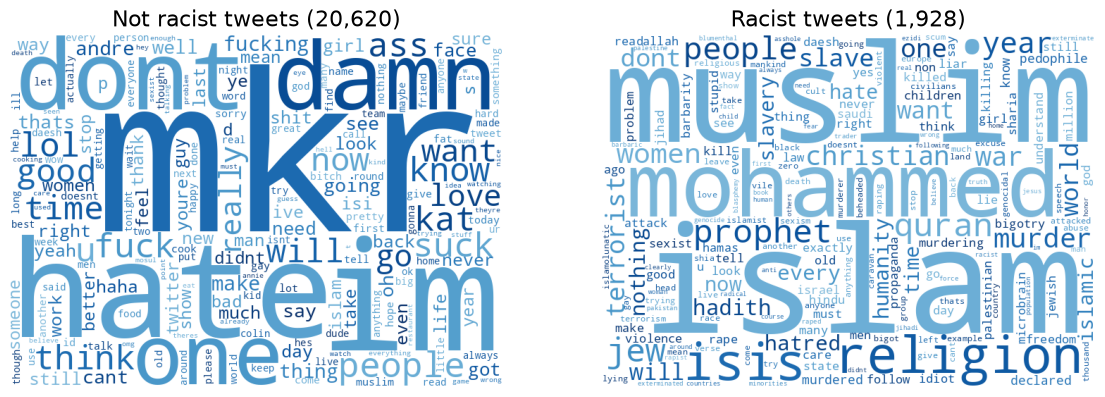

In [27]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from wordcloud import WordCloud

dark_blues = ListedColormap(plt.cm.Blues(np.linspace(0.45, 1, 256)))  # no near-white shades on a white background
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, group) in zip(axes, (("Not racist", normal), ("Racist", racist)), strict=True):
    words = " ".join(SLURS.sub("slur", text) for text in group["text_words"])
    cloud = WordCloud(width=700, height=500, background_color="white", colormap=dark_blues, collocations=False,
                      random_state=SEED).generate(words)
    ax.imshow(cloud)
    ax.axis("off")
    ax.set_title(f"{title} tweets ({len(group):,})", fontsize=16)
plt.show()

The racist tweets' vocabulary is dominated by Islam and religion, which matches what the dataset's authors searched for when collecting it. A model trained here learns that vocabulary, which is useful for this data and a risk elsewhere: it may flag any tweet that mentions Islam.

Note also how large *hate* is among the **not** racist tweets: mostly viewers hating a contestant on *My Kitchen Rules*. A word alone does not make a tweet hateful, which is why keyword lists make poor detectors and models that read context do better.

### Countries: the 2021 location analysis, with what is available now

The 2021 notebook standardised each user's self-reported location with dataprep's `clean_country`, then counted racist tweets per country:

```python
from dataprep.clean import clean_country
tweetstmp = clean_country(tweetstmp, 'user_location')
```

The location field cannot be recovered, and dataprep's last release needs Python below 3.11 and pandas below 2, so it cannot run beside this notebook. `country_converter` does the same standardisation today. The next cell shows it on a few location strings, then turns it on the tweets themselves: it counts the countries the tweets *mention*, which says nothing about where their authors live.

In [28]:
import logging

import country_converter as coco

logging.getLogger("country_converter").setLevel(logging.ERROR)  # it logs every name it cannot match
locations = ["USA", "U.K.", "united states of america", "india", "Deutschland", "somewhere over the rainbow"]
print(pd.Series(coco.convert(locations, to="name_short", not_found="not found"), index=locations).to_string(), "\n")

patterns = coco.CountryConverter().data[["name_short", "regex"]]
mentioned = pd.DataFrame({row.name_short: tweets["text_bert"].str.count(row.regex, flags=re.IGNORECASE) > 0
                          for row in patterns.itertuples()})
mentioned.groupby(tweets["annotation"]).sum().T.sort_values("racism", ascending=False).head(8)

USA                            United States
U.K.                          United Kingdom
united states of america       United States
india                                  India
Deutschland                        not found
somewhere over the rainbow         not found 



annotation,none,racism
Palestine,26,58
Israel,30,56
Pakistan,7,24
Iraq,85,14
Egypt,34,13
Iran,31,11
India,17,10
Syria,71,7


The converter standardises spellings it knows and leaves the rest: *Deutschland* stays unmatched, because it reads English names, so a real location field would need translating first. On the tweets, the countries tell the same story as the vocabulary. Relative to each class's size (1,928 racist and 20,620 non-racist tweets), the racist tweets name Israel, Palestine and Pakistan between 20 and 37 times as often as the non-racist ones, and Iraq and Syria at under twice the rate. These are countries named in the text, not where the authors live, and a pattern can match a word that is not a country at all. No model in this notebook uses them.

### The 2021 exploration steps, revisited

| 2021 step | Purpose | What changed and why |
|---|---|---|
| one example of each class | a first look | slurs masked |
| `tweets.count()` | non-missing values per column | checks that fail loudly when values are missing (sections 2 and 3) |
| class counts | the imbalance | on all the tweets, as a description; every setting a model depends on is computed from the training tweets |
| sentiment per class | how tone differs by class | shares within each class, since the classes differ so much in size |
| tweets per user location and class | geography | the location field cannot be recovered; the technique is shown on the countries the tweets mention, with `country_converter` |
| top 1-, 2- and 3-word phrases | vocabulary per class | kept, slurs masked |
| word clouds | vocabulary at a glance | kept, in colours readable on white |

## 6. A baseline every model must beat

Only about 8.6% of tweets are racist. That makes **accuracy** misleading: a "model" that answers *not racist* every time is right more than 90% of the time and catches no racist tweet at all (next cell). So models here are scored on the racist class:

- **precision**: of the tweets a model flags, the share that are racist;
- **recall**: of the racist tweets, the share it catches;
- **F1**: one number that balances the two;
- **PR-AUC** (area under the precision-recall curve): how good the trade-off is across every possible cut-off. Random guessing scores about 0.09, the share of racist tweets; a perfect model scores 1.
- **ROC-AUC**, which the 2021 notebook reported, is shown as well, but it flatters imbalanced data, because it also rewards ranking the many easy non-racist tweets.

A model outputs a probability, and a **threshold** turns it into yes or no. With class weights the best threshold is rarely 0.5, so it is chosen on the validation tweets, never on the test tweets.

Before any neural network comes a simple model: count words (TF-IDF) and fit a logistic regression. If BERT cannot beat it, BERT's size is not paying for itself.

In [29]:
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score


def scores(labels: np.ndarray, probabilities: np.ndarray) -> dict[str, float]:
    """Scores for the racist class, with precision and recall at the threshold that maximises F1."""
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    best = f1[:-1].argmax()
    return {"PR-AUC": average_precision_score(labels, probabilities), "ROC-AUC": roc_auc_score(labels, probabilities),
            "F1 at 0.5": f1_score(labels, probabilities >= 0.5), "best F1": f1[best], "threshold": thresholds[best],
            "precision": precision[best], "recall": recall[best]}


results = {}
y_train, y_validation, y_test = train["label"].to_numpy(), validation["label"].to_numpy(), test["label"].to_numpy()
always_none = np.zeros(len(y_validation), dtype=int)
print(f"always 'not racist': accuracy {(always_none == y_validation).mean():.1%}, "
      f"racist tweets caught {(always_none & y_validation).sum()} of {y_validation.sum()}")

always 'not racist': accuracy 91.5%, racist tweets caught 0 of 289


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
baseline = LogisticRegression(class_weight="balanced", max_iter=2000).fit(vectorizer.fit_transform(train["text_words"]), y_train)
validation_probabilities = baseline.predict_proba(vectorizer.transform(validation["text_words"]))[:, 1]
results["TF-IDF + logistic regression"] = scores(y_validation, validation_probabilities)
pd.DataFrame(results).T.round(3)

,PR-AUC,ROC-AUC,F1 at 0.5,best F1,threshold,precision,recall
TF-IDF + logistic regression,0.705,0.969,0.702,0.727,0.61,0.669,0.796


The vectoriser learns its vocabulary from the training tweets only, then applies it to the validation tweets: the "learned step" rule from section 3. In a few seconds, counting words already catches most racist tweets. The bar is high because the racist tweets here share a narrow vocabulary (section 5).

## 7. The text model: BERT-large, CNN and BiLSTM

```
tweet -> BERT preprocessor -> BERT-large (frozen) -> one 1,024-number vector per token
      -> 4 x Conv1D (windows of 2-5 tokens) -> max pooling -> dropout -> concatenate
      -> BiLSTM(32) -> dropout -> Dense(1, sigmoid) -> probability that the tweet is racist
```

These are the 2021 models from TensorFlow Hub: BERT-large (24 layers, 1,024 numbers per token) and its preprocessor. The 2021 code follows TensorFlow Hub's documentation for this exact model, whose example takes `pooled_output` and says either output can feed further model building; TensorFlow's BERT tutorials classify from `pooled_output` with one dense layer (the sources follow the results below). Adding a CNN and a BiLSTM changes what the input needs to be, so this section trains both wirings side by side, then traces where the 2021 wiring came from and why its training took hours.

BERT stays **frozen**, as in 2021 (`trainable=False` is the default): its 335 million weights never change, so its output for a tweet is always the same. That allows a large saving: run BERT once per tweet, keep the outputs, and train the CNN-BiLSTM head on them. The 2021 notebook re-ran BERT on every tweet in every epoch, up to 100 times.

The head has a name in the literature: a CNN-RNN hybrid, the family of Zhang and Luo's (2018) CNN-and-GRU model for this dataset. It resembles a transformer in purpose, since both mix information across a tweet's tokens, but not in mechanism. Each Conv1D filter applies the same weights to every window of 2 to 5 tokens, and the BiLSTM carries context one step at a time; self-attention weighs every token against every other, with weights computed from the tokens themselves. BERT has already applied 24 layers of self-attention before the head sees a token, so the head detects local patterns on top of a transformer rather than replacing one.

First, the preprocessor, and how long the tweets are in BERT's tokens. Importing TensorFlow Hub prints a deprecation warning about `pkg_resources`: it is harmless, and it is why `pyproject.toml` keeps `setuptools` below version 82, which removed that module.

In [31]:
import tensorflow_hub as hub
import tensorflow_text  # noqa: F401  (registers the text operations the preprocessor uses)

keras = tf.keras
preprocessor = hub.load("https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3")
tokenize = hub.KerasLayer(preprocessor.tokenize)

pieces = tokenize(tf.constant(train["text_bert"].tolist())).merge_dims(-2, -1).row_lengths().numpy() + 2  # [CLS] and [SEP]
print(f"tokens per training tweet: median {np.median(pieces):.0f}, 99th percentile {np.percentile(pieces, 99):.0f}, "
      f"longest {pieces.max()} | fit in 64: {(pieces <= 64).mean():.1%}, in 128: {(pieces <= 128).mean():.1%}")
print(f"share of BERT's input that is padding: {1 - np.minimum(pieces, 64).mean() / 64:.0%} at 64 tokens, "
      f"{1 - np.minimum(pieces, 128).mean() / 128:.0%} at 128")
print(f"tweets longer than 64 tokens: {(pieces > 64).sum()}, racist among them: {(pieces[y_train == 1] > 64).sum()} "
      f"(the longest racist tweet has {pieces[y_train == 1].max()} tokens)")

/home/josh/.venvs/dissertation/lib/python3.12/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


tokens per training tweet: median 22, 99th percentile 45, longest 263 | fit in 64: 99.8%, in 128: 100.0%
share of BERT's input that is padding: 65% at 64 tokens, 83% at 128
tweets longer than 64 tokens: 35, racist among them: 0 (the longest racist tweet has 42 tokens)


Almost every tweet fits in 64 tokens, so 64 replaces the preprocessor's default of 128. A length chosen from the distribution, rather than from the longest text, keeps one outlier from setting the cost for every tweet; the third line checks what that costs, by class, because truncation that falls unevenly on one class biases the model. 64 halves BERT's input, though most of it is still padding (second line). The preprocessor is used in its two halves, `tokenize` and `bert_pack_inputs`, because packing is where the length is set; called whole, it pads every tweet to 128. Padding each batch only to its own longest tweet, called *dynamic padding*, is the standard way to save more.

The next cell is the 2021 notebook's "test the encoder" step, printing shapes rather than values. The shapes are what decide which output a CNN can use.

In [32]:
SEQ_LENGTH = 64
pack = hub.KerasLayer(preprocessor.bert_pack_inputs, arguments={"seq_length": SEQ_LENGTH})
encoder = hub.KerasLayer("https://tfhub.dev/tensorflow/bert_en_uncased_L-24_H-1024_A-16/4", trainable=False)

inputs = pack([tokenize(tf.constant(["the weather is lovely today", "hello darling"]))])
outputs = encoder(inputs)
print("preprocessor outputs:", {name: tuple(value.shape) for name, value in inputs.items()})
print("sequence_output:", tuple(outputs["sequence_output"].shape), "| pooled_output:", tuple(outputs["pooled_output"].shape))
print("real tokens per sentence (sum of input_mask):", inputs["input_mask"].numpy().sum(axis=1))
print("word ids for 'hello darling':", inputs["input_word_ids"].numpy()[1, :6])

preprocessor outputs: {'input_mask': (2, 64), 'input_word_ids': (2, 64), 'input_type_ids': (2, 64)}
sequence_output: (2, 64, 1024) | pooled_output: (2, 1024)
real tokens per sentence (sum of input_mask): [7 4]
word ids for 'hello darling': [ 101 7592 9548  102    0    0]


- `input_word_ids` are positions in BERT's vocabulary. For "hello darling": 101 is `[CLS]`, which opens every input; 7592 is *hello*; 9548 is *darling*; 102 is `[SEP]`, which closes it; then zeros, the padding.
- `input_mask` marks real tokens with 1 and padding with 0: 7 real tokens in the first sentence, 4 in the second.
- `sequence_output` is `(2, 64, 1024)`: 2 sentences, 64 positions each, and at every position 1,024 numbers describing that token in the context of the whole sentence. No single number means anything alone; together they place the token where words used in similar ways sit close.
- `pooled_output` is `(2, 1024)`: one vector per sentence, built for a single classification layer.

A CNN or a BiLSTM reads **positions in order**, so it needs `sequence_output`, with the padding positions zeroed so that they carry nothing.

Next, BERT runs once over every tweet, in batches of 32, which fit a 4 GB GPU. This takes about five minutes. The outputs are kept in half precision (`float16`, about three significant digits), which halves the memory.

In [33]:
import time


def bert_outputs(texts: list[str], batch: int = 32) -> dict[str, np.ndarray]:
    """Frozen BERT-large outputs for each text: sequence (float16), pooled, and the padding mask."""
    parts = {"sequence": [], "pooled": [], "mask": []}
    for start in range(0, len(texts), batch):
        inputs = pack([tokenize(tf.constant(texts[start:start + batch]))])
        outputs = encoder(inputs)
        parts["sequence"].append(outputs["sequence_output"].numpy().astype(np.float16))
        parts["pooled"].append(outputs["pooled_output"].numpy())
        parts["mask"].append(inputs["input_mask"].numpy().astype(np.float16))
    return {name: np.concatenate(arrays) for name, arrays in parts.items()}


started = time.perf_counter()
bert = {name: bert_outputs(part["text_bert"].tolist()) for name, part in splits.items()}
bert_seconds = time.perf_counter() - started
tweet_count = sum(len(arrays["mask"]) for arrays in bert.values())
print(f"BERT-large ran once over {tweet_count:,} tweets in {bert_seconds / 60:.1f} minutes")
print({name: f"{len(arrays['mask']):,} tweets, {arrays['sequence'].nbytes / 2**30:.2f} GB" for name, arrays in bert.items()})

BERT-large ran once over 22,548 tweets in 4.9 minutes
{'train': '15,783 tweets, 1.93 GB', 'validation': '3,382 tweets, 0.41 GB', 'test': '3,383 tweets, 0.41 GB'}


### Training the head

Three pieces, all following the 2021 notebook:

- **Class weights**: the 2021 idea, kept. Each racist tweet counts for more in the loss, in proportion to how rare it is. Oversampling the racist tweets, or SMOTE for numeric features, would do the same job; class weights do it without copied or synthetic examples. Current scikit-learn requires its arguments by keyword.
- **The head**: the 2021 layers with their 2021 names and settings, written once as a function so both versions share it exactly.
- **Training**: the 2021 optimiser (Adam, learning rate 5e-5), loss, epochs (100) and patience (5). Early stopping now watches the **validation** PR-AUC instead of the training loss, which keeps falling as a model memorises its training tweets, and it restores the best epoch's weights.
- **Batch size**: 32, as in 2021. It sets how noisy each step's estimate of the gradient is, and it interacts with the learning rate: [Goyal et al. (2017)](https://arxiv.org/abs/1706.02677) scale the rate with the batch. Memory caps it, since a 4 GB GPU holds only so many tweets at once; *gradient accumulation*, which sums several small batches' gradients before one update, gives a larger effective batch without the memory.

`Batches` feeds the saved BERT outputs to Keras one batch of 32 at a time. Handing Keras the whole array instead makes it copy all of it at once, in full precision, which can exhaust memory.

In [34]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = dict(enumerate(compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)))
print("class weights:", {label: round(float(weight), 3) for label, weight in class_weights.items()})

class weights: {0: 0.547, 1: 5.846}


In [35]:
class Batches(keras.utils.Sequence):
    """Feeds saved arrays to Keras one batch at a time, converting each batch to float32 as it goes."""

    def __init__(self, arrays: list[np.ndarray], labels: np.ndarray, batch: int = 32, shuffle: bool = False):
        self.arrays, self.labels, self.batch, self.shuffle = arrays, labels, batch, shuffle
        self.order = np.arange(len(labels))

    def __len__(self) -> int:
        return -(-len(self.labels) // self.batch)

    def __getitem__(self, i: int) -> tuple[list[np.ndarray], np.ndarray]:
        rows = self.order[i * self.batch:(i + 1) * self.batch]
        return [array[rows].astype(np.float32) for array in self.arrays], self.labels[rows]

    def on_epoch_end(self) -> None:
        if self.shuffle:
            np.random.shuffle(self.order)


def cnn_bilstm_head(x, l2=0.1):
    """The 2021 head: Conv1D windows of 2-5 positions, max pooling, dropout, a BiLSTM and a sigmoid output.
    `l2` is the 2021 penalty unless given."""
    branches = []
    for i, size in enumerate((2, 3, 4, 5), start=1):
        cnn = keras.layers.Conv1D(64, size, activation="relu", padding="same",
                                  kernel_regularizer=keras.regularizers.l2(l2), name=f"cnn{i}")(x)
        pool = keras.layers.MaxPooling1D(pool_size=2, name=f"pool{i}")(cnn)
        branches.append(keras.layers.Dropout(0.1, name=f"dropout{i}")(pool))
    x = keras.layers.Bidirectional(keras.layers.LSTM(32), name="bi-lstm1")(keras.layers.concatenate(branches, name="concat"))
    x = keras.layers.Dropout(0.1, name="dropout5")(x)
    return keras.layers.Dense(1, activation="sigmoid", name="bert_outputs")(x)


def train_head(model, train_arrays: list[np.ndarray], validation_arrays: list[np.ndarray], lr: float = 5e-5,
               batch: int = 32) -> np.ndarray:
    """Trains with the 2021 settings (unless `lr` or `batch` is given) and early stopping on validation PR-AUC; returns
    validation probabilities."""
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    stop = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True)
    validation_batches = Batches(validation_arrays, y_validation)
    model.fit(Batches(train_arrays, y_train, batch, shuffle=True), validation_data=validation_batches, epochs=100,
              class_weight=class_weights, callbacks=[stop], verbose=2)
    return model.predict(validation_batches, verbose=0).ravel()

### Version A: the 2021 wiring

`pooled_output` (1,024 numbers) reshaped to `(1024, 1)`: the CNN slides its windows along the 1,024 numbers of one summary vector, as if they were words in a sentence. The summary shows what that means for the layers: each Conv1D window covers a few *numbers*, and the BiLSTM reads 512 "steps".

In [36]:
tf.keras.utils.set_random_seed(SEED)
pooled_input = keras.Input(shape=(1024,), name="pooled_output")
model_a = keras.Model(pooled_input, cnn_bilstm_head(keras.layers.Reshape((1024, 1), name="reshape1")(pooled_input)))
model_a.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 pooled_output (InputLayer)  [(None, 1024)]               0         []                            
                                                                                                  
 reshape1 (Reshape)          (None, 1024, 1)              0         ['pooled_output[0][0]']       
                                                                                                  
 cnn1 (Conv1D)               (None, 1024, 64)             192       ['reshape1[0][0]']            
                                                                                                  
 cnn2 (Conv1D)               (None, 1024, 64)             256       ['reshape1[0][0]']            
                                                                                              

In [37]:
results["A: 2021 wiring (pooled_output)"] = scores(y_validation, train_head(model_a, [bert["train"]["pooled"]],
                                                                          [bert["validation"]["pooled"]]))
pd.DataFrame(results).T.round(3)

Epoch 1/100
494/494 - 51s - loss: 1.3262 - pr_auc: 0.1600 - val_loss: 1.1935 - val_pr_auc: 0.2307 - 51s/epoch - 103ms/step
Epoch 2/100
494/494 - 42s - loss: 1.0782 - pr_auc: 0.2080 - val_loss: 1.0708 - val_pr_auc: 0.2375 - 42s/epoch - 86ms/step
Epoch 3/100
494/494 - 43s - loss: 0.9347 - pr_auc: 0.2205 - val_loss: 0.9558 - val_pr_auc: 0.2398 - 43s/epoch - 86ms/step
Epoch 4/100
494/494 - 42s - loss: 0.8607 - pr_auc: 0.2370 - val_loss: 0.8516 - val_pr_auc: 0.2407 - 42s/epoch - 85ms/step
Epoch 5/100
494/494 - 42s - loss: 0.8165 - pr_auc: 0.2315 - val_loss: 0.7112 - val_pr_auc: 0.2398 - 42s/epoch - 85ms/step
Epoch 6/100
494/494 - 42s - loss: 0.7876 - pr_auc: 0.2321 - val_loss: 0.9591 - val_pr_auc: 0.2460 - 42s/epoch - 85ms/step
Epoch 7/100
494/494 - 42s - loss: 0.7632 - pr_auc: 0.2331 - val_loss: 0.8670 - val_pr_auc: 0.2454 - 42s/epoch - 85ms/step
Epoch 8/100
494/494 - 43s - loss: 0.7449 - pr_auc: 0.2381 - val_loss: 0.7027 - val_pr_auc: 0.2476 - 43s/epoch - 88ms/step
Epoch 9/100
494/494 - 4

,PR-AUC,ROC-AUC,F1 at 0.5,best F1,threshold,precision,recall
TF-IDF + logistic regression,0.705,0.969,0.702,0.727,0.610,0.669,0.796
A: 2021 wiring (pooled_output),0.264,0.821,0.298,0.365,0.746,0.316,0.433


### Version B: the corrected wiring

The same head, the same settings, a different input: `sequence_output`, one vector per token, with the padding positions zeroed by the mask. Each Conv1D window now covers 2-5 real **tokens**, and the BiLSTM reads 32 positions in order. Since nothing else changes, any difference between A and B is the effect of the wiring alone.

In [38]:
tf.keras.utils.set_random_seed(SEED)
sequence_input = keras.Input(shape=(SEQ_LENGTH, 1024), name="sequence_output")
mask_input = keras.Input(shape=(SEQ_LENGTH,), name="input_mask")
mask = keras.layers.Reshape((SEQ_LENGTH, 1), name="reshape_mask")(mask_input)
masked_sequence = keras.layers.Multiply(name="masked_sequence")([sequence_input, mask])
model_b = keras.Model([sequence_input, mask_input], cnn_bilstm_head(masked_sequence))

In [39]:
model_b.summary()
results["B: corrected wiring (sequence_output, padding masked)"] = scores(
    y_validation, train_head(model_b, [bert["train"]["sequence"], bert["train"]["mask"]],
                             [bert["validation"]["sequence"], bert["validation"]["mask"]]))
pd.DataFrame(results).T.round(3)

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_mask (InputLayer)     [(None, 64)]                 0         []                            
                                                                                                  
 sequence_output (InputLaye  [(None, 64, 1024)]           0         []                            
 r)                                                                                               
                                                                                                  
 reshape_mask (Reshape)      (None, 64, 1)                0         ['input_mask[0][0]']          
                                                                                                  
 masked_sequence (Multiply)  (None, 64, 1024)             0         ['sequence_output[0][0]'

,PR-AUC,ROC-AUC,F1 at 0.5,best F1,threshold,precision,recall
TF-IDF + logistic regression,0.705,0.969,0.702,0.727,0.610,0.669,0.796
A: 2021 wiring (pooled_output),0.264,0.821,0.298,0.365,0.746,0.316,0.433
"B: corrected wiring (sequence_output, padding masked)",0.747,0.977,0.672,0.745,0.865,0.663,0.851


### Where the 2021 wiring came from

The 2021 BERT code follows the documentation for this exact model and the tutorials of the time:

- TensorFlow Hub's page for `bert_en_uncased_L-24_H-1024_A-16/4` ([the June 2021 version](https://github.com/tensorflow/tfhub.dev/blob/b9946022b8ea77536f4e46af2ab97b210f8bcf0b/assets/docs/tensorflow/models/bert_en_uncased_L-24_H-1024_A-16/4.md)) shows both outputs, says "Either of those can be used as input to further model building", and builds `embedding_model = tf.keras.Model(text_input, pooled_output)`.
- TensorFlow's own tutorial, [*Classify text with BERT*](https://www.tensorflow.org/text/tutorials/classify_text_with_bert), builds its classifier as `outputs['pooled_output']`, then dropout, then one dense layer, and says: "For the fine-tuning you are going to use the `pooled_output` array" ([the May 2021 version](https://github.com/tensorflow/text/blob/eb31ab0001bf42041322d05bcd930c7b3fc9707d/docs/tutorials/classify_text_with_bert.ipynb)).
- codebasics' BERT tutorial ([notebook, August 2021](https://github.com/codebasics/deep-learning-keras-tf-tutorial/blob/master/47_BERT_text_classification/BERT_email_classification-handle-imbalance.ipynb)) loads the preprocessor and encoder the same way as the 2021 notebook, defines the same `get_sentence_embeding` function, and also feeds `pooled_output` to one dense layer.

For one dense layer, `pooled_output` is the right input. The 2021 model put a CNN and a BiLSTM in that place. Those layers look for patterns across neighbouring positions, so they need one vector per position: `sequence_output`. Neither tutorial covers that case, and the reshape to `(1024, 1)` runs without an error, so nothing signalled the mismatch.

Freezing made the pooled vector weaker still. The TensorFlow tutorial fine-tunes BERT (`trainable=True`), so its pooled vector adapts to the task; codebasics' tutorial and the 2021 code keep the default, frozen, although the model's own page calls fine-tuning all parameters "the recommended practice". Frozen, `pooled_output` is the `[CLS]` token's vector passed through a layer trained for one of BERT's pre-training tasks: predicting whether one sentence follows another. Hugging Face's documentation said so at the time: "This output is usually *not* a good summary of the semantic content of the input, you're often better with averaging or pooling the sequence of hidden-states for the whole input sequence" ([transformers 4.10, August 2021](https://github.com/huggingface/transformers/blob/v4.10.0/src/transformers/modeling_tf_outputs.py)).

**The check that catches this kind of mistake:** at every boundary between two components, print the shape and say what each axis means. `Conv1D` reads its input as (positions, numbers per position), so `(1024, 1)` means 1,024 positions holding one number each, and those positions are the numbers of a single vector, not words. Versions A and B above measure what that costs.

### Why training took hours in 2021, and minutes here

The GPU Colab assigned played a part, but the design did most of it:

| | 2021 | This notebook |
|---|---|---|
| BERT-large | inside the model: run over every training tweet in every epoch | run once per tweet; the outputs are saved |
| Tokens per tweet | 128, the preprocessor's default | 64 |
| Epochs | up to 100: early stopping watched the training loss, which keeps falling as a model memorises its data, so it seldom stops early | stops when validation PR-AUC stops improving |
| BiLSTM | 512 steps (the 1,024 numbers of `pooled_output`, halved by max pooling) | 32 steps (64 positions, halved) |

`trainable=False` stops BERT's weights from changing, not its cost: as long as BERT sits inside the model, Keras runs all 24 layers for every batch of every epoch. Running a frozen network once and training only the layers after it on its saved outputs is called **feature extraction** (or caching embeddings), and it applies to any model with a frozen front part. The BiLSTM adds its own cost, because each of its steps waits for the previous one; compare the seconds per epoch Keras printed for versions A and B.

The next cell times BERT-large on this machine at both lengths and works out what the 2021 design would spend on BERT alone.

In [40]:
timing_texts = train["text_bert"].tolist()[:640]
seconds_per_tweet = {}
for length in (64, 128):
    packer = hub.KerasLayer(preprocessor.bert_pack_inputs, arguments={"seq_length": length})
    encoder(packer([tokenize(tf.constant(timing_texts[:32]))]))  # the first call at a length builds the graph: not timed
    started = time.perf_counter()
    for start in range(0, len(timing_texts), 32):
        encoder(packer([tokenize(tf.constant(timing_texts[start:start + 32]))]))["sequence_output"].numpy()
    seconds_per_tweet[length] = (time.perf_counter() - started) / len(timing_texts)

bert_2021_epoch = len(train) * seconds_per_tweet[128]
print(f"BERT-large per tweet: {1000 * seconds_per_tweet[64]:.1f} ms at 64 tokens, {1000 * seconds_per_tweet[128]:.1f} ms at 128")
print(f"2021 design, BERT alone: {bert_2021_epoch / 60:.1f} minutes per epoch over {len(train):,} training tweets, "
      f"{100 * bert_2021_epoch / 3600:.1f} hours for 100 epochs")
print(f"this notebook: BERT once over all {tweet_count:,} tweets, {bert_seconds / 60:.1f} minutes")

BERT-large per tweet: 13.0 ms at 64 tokens, 25.2 ms at 128
2021 design, BERT alone: 6.6 minutes per epoch over 15,783 training tweets, 11.0 hours for 100 epochs
this notebook: BERT once over all 22,548 tweets, 4.9 minutes


A faster GPU shortens every line above; the gap between the two designs comes from the design itself. The 2021 notebook paid BERT's cost once per epoch, this one pays it once.

### Version C: the corrected model, tuned

Versions A and B keep every 2021 training setting, so that their comparison isolates the wiring. With the wiring fixed, the settings themselves can be tuned, on the validation tweets only. The rebuild searched the 2021 architecture's settings in three steps:

1. **Five deliberate points**, varying one or two settings at a time.
2. **A random search** of 16 settings: learning rate 1e-4 to 5e-4, L2 1e-4 to 1e-2, dropout 0.1 or 0.3, 64 or 128 filters, 32 or 64 LSTM units, batch 32 or 64, with or without an extra dense layer. Random search covers the settings that matter better than a grid of the same size (Bergstra and Bengio, 2012).
3. **The two best, with three more seeds each**, deterministic and with full patience.

| Setting | Search | Seeds 1, 2, 3 |
|---|---|---|
| 2021: learning rate 5e-5, L2 0.1, 64 filters, LSTM 32 | 0.757 | |
| learning rate 2e-4, L2 1e-3, 64 filters, LSTM 32 | 0.787 | 0.819, 0.800, 0.807 |
| learning rate 2e-4, L2 1e-4, 128 filters, LSTM 64 | 0.804 | 0.800, 0.802, 0.808 |

The learning rate mattered most: 5e-5 is a rate for fine-tuning BERT itself, too slow for new layers. The 2021 L2 of 0.1 held the CNN back. Batch 32 beat 64, and neither an extra dense layer nor more dropout helped. The two finalists tie within the seed-to-seed noise, so version C takes the simpler one: the 2021 architecture, layer sizes and all, with two settings changed, learning rate 2e-4 and L2 1e-3. (The search's own score for it is lower because the search stopped after 3 epochs without improvement, and this setting peaks late.)

During the final review the search was widened: 49 settings drawn at random across ten settings at once (learning rate 5e-5 to 1e-3, L2 0 to 0.01, dropout 0.1 to 0.5, 32 to 256 filters, windows of 1-4, 2-5 or 3-6 tokens, pooling 2 or 4, 16 to 128 LSTM units, batch 16 to 64, an extra dense layer, and class weights balanced, square-root or none), then the four best with three seeds each. The rule for ties was fixed before any result: a setting replaces version C only if its mean over the seeds beats C's by more than the seeds' own spread.

| Setting from the wider search | Its single run | Seeds 1, 2, 3 | Mean |
|---|---|---|---|
| 32 filters, learning rate 5e-4, dropout 0.3, square-root class weights | 0.827 | 0.825, 0.802, 0.828 | 0.818 |
| 32 filters, learning rate 2e-4, dropout 0.5, no class weights | 0.819 | 0.823, 0.823, 0.801 | 0.816 |
| 32 filters, learning rate 3e-4, an extra dense layer, square-root class weights | 0.833 | 0.827, 0.794, 0.811 | 0.811 |
| 256 filters, learning rate 1e-4, an extra dense layer, square-root class weights | 0.821 | 0.816, 0.793, 0.815 | 0.808 |
| version C | 0.778 | 0.819, 0.800, 0.807 | 0.809 |

The best single run, 0.833, fell to 0.811 over three seeds: picking the top of 49 noisy runs selects partly for luck, the *winner's curse*, and the seeds take the luck back out. No setting beat version C by more than the spread of its seeds, so version C stays. The search hinted that the 2021 class weighting hurt, so it was tested alone: version C with square-root weights scored 0.814, and with none 0.813, over the same three seeds, again within the spread. Without class weights the seeds varied least (0.810 to 0.817, against 0.800 to 0.819): weighting the racist tweets nearly eleven times as heavily as the rest made training noisier without ranking the tweets better.

In [41]:
tf.keras.utils.set_random_seed(SEED)
sequence_input = keras.Input(shape=(SEQ_LENGTH, 1024), name="sequence_output")
mask_input = keras.Input(shape=(SEQ_LENGTH,), name="input_mask")
mask = keras.layers.Reshape((SEQ_LENGTH, 1), name="reshape_mask")(mask_input)
masked_sequence = keras.layers.Multiply(name="masked_sequence")([sequence_input, mask])
model_c = keras.Model([sequence_input, mask_input], cnn_bilstm_head(masked_sequence, l2=1e-3))
results["C: corrected wiring, tuned"] = scores(
    y_validation, train_head(model_c, [bert["train"]["sequence"], bert["train"]["mask"]],
                             [bert["validation"]["sequence"], bert["validation"]["mask"]], lr=2e-4))
pd.DataFrame(results).T.round(3)

Epoch 1/100
494/494 - 27s - loss: 0.6505 - pr_auc: 0.6690 - val_loss: 0.6855 - val_pr_auc: 0.7444 - 27s/epoch - 55ms/step
Epoch 2/100
494/494 - 22s - loss: 0.4914 - pr_auc: 0.7188 - val_loss: 0.7271 - val_pr_auc: 0.7203 - 22s/epoch - 45ms/step
Epoch 3/100
494/494 - 22s - loss: 0.4074 - pr_auc: 0.7311 - val_loss: 0.4301 - val_pr_auc: 0.7379 - 22s/epoch - 45ms/step
Epoch 4/100
494/494 - 22s - loss: 0.3381 - pr_auc: 0.7630 - val_loss: 0.3314 - val_pr_auc: 0.7464 - 22s/epoch - 44ms/step
Epoch 5/100
494/494 - 22s - loss: 0.2933 - pr_auc: 0.7648 - val_loss: 0.3025 - val_pr_auc: 0.7563 - 22s/epoch - 45ms/step
Epoch 6/100
494/494 - 22s - loss: 0.2573 - pr_auc: 0.7814 - val_loss: 0.3132 - val_pr_auc: 0.7691 - 22s/epoch - 44ms/step
Epoch 7/100
494/494 - 22s - loss: 0.2391 - pr_auc: 0.7844 - val_loss: 0.2937 - val_pr_auc: 0.7667 - 22s/epoch - 45ms/step
Epoch 8/100
494/494 - 22s - loss: 0.2171 - pr_auc: 0.7947 - val_loss: 0.2599 - val_pr_auc: 0.7845 - 22s/epoch - 44ms/step
Epoch 9/100
494/494 - 22

,PR-AUC,ROC-AUC,F1 at 0.5,best F1,threshold,precision,recall
TF-IDF + logistic regression,0.705,0.969,0.702,0.727,0.610,0.669,0.796
A: 2021 wiring (pooled_output),0.264,0.821,0.298,0.365,0.746,0.316,0.433
"B: corrected wiring (sequence_output, padding masked)",0.747,0.977,0.672,0.745,0.865,0.663,0.851
"C: corrected wiring, tuned",0.819,0.980,0.750,0.752,0.509,0.678,0.844


### The 2021 model-building steps, revisited

| 2021 step | Purpose | What changed and why |
|---|---|---|
| BERT-large and its preprocessor from TensorFlow Hub | text to token vectors | the same models, frozen, now served from Kaggle Models; 64 tokens instead of the default 128 |
| `get_sentence_embeding` | check the encoder's output | prints the shapes of both outputs, which decide what each layer can use |
| 80/20 split | train and test sets | one seeded 70/15/15 split shared by every model (section 4) |
| `pooled_output` reshaped to `(1024, 1)`, then CNN and BiLSTM | the documented output, given the shape the layers need | kept as version A; version B feeds `sequence_output` |
| `model.summary()` | layer shapes | shown for versions A and B |
| Adam 5e-5, binary cross-entropy | training setup | kept for versions A and B; version C uses learning rate 2e-4 and L2 1e-3, chosen on validation; PR-AUC tracked beside the loss |
| early stopping on the loss | stop once training stops improving | on validation PR-AUC, measured on tweets the model has not trained on |
| class weights | balance the rare class | kept, called with keyword arguments as scikit-learn now requires |
| `fit(epochs=100)` on the text | train the model | BERT run once and its outputs saved, so each model trains in minutes |
| `reset_states()` | clear the LSTM's memory between uses | not needed: Keras clears it after every sequence, and it never changes the weights |
| saving and reloading the model | reuse it without training | section 10 |
| test evaluation, ROC-AUC, confusion matrix, sample predictions | final results | section 9 |

## 8. The numeric model and the hybrid

The 2021 notebook's second idea: describe each tweet with numbers (section 3: counts, readability, VADER sentiment), train a small network on them, and fuse it with the text model. Three steps follow: scale the features, train the numeric model on its own to measure what the features achieve alone, then fuse it with the text model in two ways.

In current terms this is a **multimodal** model: two kinds of input, text and tabular features, each read by its own branch. In 2021 the numbers included facts about each tweet's author, a second source of information; here every feature is computed from the tweet's own text (section 3), so the two branches read one source in two ways.

The features sit on very different scales: characters run into the hundreds, shares from 0 to 1, and reading ease mostly from -50 to 120, with one tweet at -7,367. A network trains badly on inputs like that, because the large ones dominate the first weights. The 2021 notebook used a `QuantileTransformer`, which replaces each value with its rank among the training tweets, from 0 to 1, so an outlier such as that -7,367, or a 1,000-character post, cannot stretch the scale. It is kept, now fitted on the training tweets only.

In [42]:
from sklearn.preprocessing import QuantileTransformer

scaler = QuantileTransformer(random_state=SEED).fit(numeric.loc[train.index])
features = {name: scaler.transform(numeric.loc[part.index]).astype(np.float32) for name, part in splits.items()}
print(f"{features['train'].shape[1]} features | training tweets scaled to "
      f"{features['train'].min():.0f}-{features['train'].max():.0f}, "
      f"validation tweets to {features['validation'].min():.2f}-{features['validation'].max():.2f}")

25 features | training tweets scaled to 0-1, validation tweets to 0.00-1.00


The numeric model, written as in 2021 with Keras's `Sequential` API: a plain stack of layers, one after another. The text model used the *functional* API instead, which can take several inputs and branch; `Sequential` is the shorter way to write a model that does neither. It trains with the same settings as the text model, except its learning rate, 1e-3 instead of 2021's 5e-5, and its batch of 128 tweets. Measured during the rebuild, on the same split: 2021's settings with the original 19 features reach a validation PR-AUC of 0.504; these 25 features at 1e-3 reach about 0.56. Searching 16 settings of learning rate, width, dropout, L2 and batch size, and networks of up to three layers and 177,665 weights, kept every score between 0.54 and 0.57, with training scores no higher than validation ones; gradient boosting, the usual strongest model for this kind of data, reached 0.575. The final review re-ran nine of those settings with five seeds each: two layers of 256 averaged 0.563 (0.560 to 0.565), against 0.555 (0.551 to 0.559) for the 2021 size of one layer of 128. The gain is small, because the 25 features hold only so much information about racism, but the ranges do not overlap, so the model below has two layers of 256.

In [43]:
tf.keras.utils.set_random_seed(SEED)
num_model = keras.Sequential([
    keras.Input(shape=(features["train"].shape[1],), name="numeric_features"),
    keras.layers.Dense(256, activation="relu", name="dense1"),
    keras.layers.Dropout(0.1, name="drop1"),
    keras.layers.Dense(256, activation="relu", name="dense2"),
    keras.layers.Dropout(0.1, name="drop2"),
    keras.layers.Dense(1, activation="sigmoid", name="dense3"),
], name="numeric_model")
results["numeric features only"] = scores(y_validation, train_head(num_model, [features["train"]], [features["validation"]],
                                                                    lr=1e-3, batch=128))
pd.DataFrame(results).T.round(3)

Epoch 1/100
124/124 - 3s - loss: 0.3909 - pr_auc: 0.4259 - val_loss: 0.3701 - val_pr_auc: 0.5197 - 3s/epoch - 22ms/step
Epoch 2/100
124/124 - 2s - loss: 0.3307 - pr_auc: 0.4787 - val_loss: 0.3570 - val_pr_auc: 0.5397 - 2s/epoch - 14ms/step
Epoch 3/100
124/124 - 2s - loss: 0.3192 - pr_auc: 0.4853 - val_loss: 0.4369 - val_pr_auc: 0.5308 - 2s/epoch - 14ms/step
Epoch 4/100
124/124 - 2s - loss: 0.3136 - pr_auc: 0.4986 - val_loss: 0.3279 - val_pr_auc: 0.5471 - 2s/epoch - 13ms/step
Epoch 5/100
124/124 - 2s - loss: 0.3094 - pr_auc: 0.5056 - val_loss: 0.3447 - val_pr_auc: 0.5516 - 2s/epoch - 13ms/step
Epoch 6/100
124/124 - 2s - loss: 0.3074 - pr_auc: 0.5108 - val_loss: 0.2835 - val_pr_auc: 0.5571 - 2s/epoch - 14ms/step
Epoch 7/100
124/124 - 2s - loss: 0.2999 - pr_auc: 0.5181 - val_loss: 0.3023 - val_pr_auc: 0.5481 - 2s/epoch - 13ms/step
Epoch 8/100
124/124 - 2s - loss: 0.2995 - pr_auc: 0.5207 - val_loss: 0.3653 - val_pr_auc: 0.5614 - 2s/epoch - 13ms/step
Epoch 9/100
124/124 - 2s - loss: 0.2961 

,PR-AUC,ROC-AUC,F1 at 0.5,best F1,threshold,precision,recall
TF-IDF + logistic regression,0.705,0.969,0.702,0.727,0.610,0.669,0.796
A: 2021 wiring (pooled_output),0.264,0.821,0.298,0.365,0.746,0.316,0.433
"B: corrected wiring (sequence_output, padding masked)",0.747,0.977,0.672,0.745,0.865,0.663,0.851
"C: corrected wiring, tuned",0.819,0.980,0.750,0.752,0.509,0.678,0.844
numeric features only,0.568,0.934,0.461,0.577,0.816,0.512,0.661


### Which features carry the signal

*Mutual information* measures how much knowing one feature reduces the uncertainty about the label: 0 when the two are independent, and more the more the feature tells. The next cell ranks the 25 features by it on the training tweets. *Mentions* comes first: the nine authors' habit of replying to other accounts (section 5).

Ranking is not selecting. During the final review the numeric model was trained on the top 5, 10, 15 and 20 features as well as all 25, nine settings each, and every cut scored lower, from about 0.38 with 5 features to 0.56 with all 25, so all 25 stay. A ranking made one feature at a time also misses what features do together. Sentiment ranks in the middle, and its seven columns alone reach only 0.204; yet removing them costs the numeric model about 0.07 (0.562 to 0.493, over five seeds). Its value lies in combination, for example negativity together with mentions and length. That is the difference between *marginal* importance, what a feature tells alone, and *conditional* importance, what it adds to the others.

In [44]:
from sklearn.feature_selection import mutual_info_classif

information = mutual_info_classif(numeric.loc[train.index], y_train, random_state=SEED)
pd.Series(information, index=numeric.columns, name="mutual information").sort_values(ascending=False).round(3)

mentions               0.074
reading_ease           0.069
grade_level            0.068
syllables              0.055
characters             0.051
average_word_length    0.050
capitals_share         0.043
words                  0.035
vader_compound         0.027
vader_positive         0.015
vader_neutral          0.010
sentiment_positive     0.010
exclamations           0.010
sentiment_negative     0.009
vader_negative         0.008
they_them              0.007
sentiment_neutral      0.005
hashtags               0.004
emoji                  0.003
links                  0.002
words_in_capitals      0.002
questions              0.002
we_us                  0.001
retweet                0.000
you                    0.000
Name: mutual information, dtype: float64

### Fusing the two models

The 2021 combined model joined the two models' **outputs**: one probability from each, concatenated, then Dense(256), dropout and a final probability. This is **late fusion**: each branch reduces its evidence to a single number before they meet, so the layers on top can only learn how far to trust each one. **Intermediate fusion** joins the branches' *hidden* layers instead: the text branch's 64 BiLSTM numbers and the numeric branch's last 256. The layers on top can then combine evidence, for example weigh negative sentiment differently when the text is about religion.

In both designs the two branches run side by side; they differ only in where they meet:

```
          2021: late fusion                          intermediate fusion
  text branch           numeric branch        text branch           numeric branch
  BERT, CNN, BiLSTM     25 features, Dense    BERT, CNN, BiLSTM     25 features, Dense
        |                     |                     |                     |
  1 probability         1 probability          64 numbers           256 numbers
         \                   /                       \                   /
          join: 2 numbers                            join: 320 numbers
                 |                                          |
      Dense 256, dropout, sigmoid                Dense 256, dropout, sigmoid
```

Both start from the tuned text model (version C) and the trained numeric model, train every layer at learning rate 0.0001 (a small rate, so the trained layers are refined rather than overwritten), and end in the 2021 fusion layers (`fusion_top` below).

How a hybrid should start was tested during the rebuild, on the validation tweets (PR-AUC, the text model alone at 0.810): a trained text branch with a fresh numeric one, 0.812; both branches trained and every layer fine-tuned at 1e-4, 0.818; both from scratch, 0.829 but the lowest F1; the fusion layers alone first and then everything at 1e-5, 0.818. All sit within the seed-to-seed noise of one another, so the notebook uses the second: it keeps the 2021 idea of building the hybrid from trained models, and it is the usual way to fine-tune a combined model. Other ways to combine two models: average their probabilities (an ensemble), or train a small model on their predictions for held-out tweets (stacking).

During the final review the fusion itself was searched: 26 settings of where the branches meet, one to three fusion layers of 64 to 512 units, dropout, learning rate, and whether to start from the trained branches or train everything fresh, end to end. The three best were re-run with three seeds beside this notebook's design, which kept the best mean, 0.823 (0.819 to 0.829). The best single runs, 0.825 and 0.820, both trained fresh with three fusion layers, fell to means of 0.816 and 0.798 once seeded: the winner's curse again.

One trap: a hybrid built from `model_c`'s layers *shares* those layers with `model_c`, so training the hybrid would silently change `model_c` as well. `trained_copy` builds a separate model with the same trained weights; the check after training confirms that `model_c` did not change.

In [45]:
def trained_copy(model):
    """A separate model with the same architecture and trained weights; training the copy leaves the original unchanged."""
    copy = keras.models.clone_model(model)
    copy.set_weights(model.get_weights())
    return copy


def fusion_top(branches):
    """The 2021 fusion layers: concatenate the branches, Dense 256, dropout, and the output probability."""
    x = keras.layers.concatenate(branches, name="combined")
    x = keras.layers.Dense(256, activation="relu", name="fdense1")(x)
    return keras.layers.Dense(1, activation="sigmoid", name="fdense2")(keras.layers.Dropout(0.1, name="fdrop1")(x))


def with_features(part: str) -> list[np.ndarray]:
    """A hybrid's three inputs for one part of the split: BERT's sequence output, its mask and the scaled features."""
    return [bert[part]["sequence"], bert[part]["mask"], features[part]]


model_c_weights = model_c.get_weights()
tf.keras.utils.set_random_seed(SEED)
text, numbers = trained_copy(model_c), trained_copy(num_model)
hybrid_2021 = keras.Model(text.inputs + numbers.inputs, fusion_top([text.output, numbers.output]))
results["hybrid, 2021 fusion of outputs"] = scores(y_validation, train_head(hybrid_2021, with_features("train"),
                                                                            with_features("validation"), lr=0.0001))
pd.DataFrame(results).T.round(3)

Epoch 1/100
494/494 - 28s - loss: 0.5680 - pr_auc: 0.7483 - val_loss: 0.6189 - val_pr_auc: 0.7701 - 28s/epoch - 57ms/step
Epoch 2/100
494/494 - 24s - loss: 0.3680 - pr_auc: 0.8054 - val_loss: 0.4412 - val_pr_auc: 0.7200 - 24s/epoch - 48ms/step
Epoch 3/100
494/494 - 24s - loss: 0.2410 - pr_auc: 0.8241 - val_loss: 0.3235 - val_pr_auc: 0.7149 - 24s/epoch - 48ms/step
Epoch 4/100
494/494 - 23s - loss: 0.1728 - pr_auc: 0.8367 - val_loss: 0.2790 - val_pr_auc: 0.7732 - 23s/epoch - 47ms/step
Epoch 5/100
494/494 - 23s - loss: 0.1326 - pr_auc: 0.8670 - val_loss: 0.2137 - val_pr_auc: 0.7714 - 23s/epoch - 47ms/step
Epoch 6/100
494/494 - 23s - loss: 0.1177 - pr_auc: 0.8724 - val_loss: 0.2302 - val_pr_auc: 0.7732 - 23s/epoch - 47ms/step
Epoch 7/100
494/494 - 24s - loss: 0.1094 - pr_auc: 0.8794 - val_loss: 0.1914 - val_pr_auc: 0.7794 - 24s/epoch - 48ms/step
Epoch 8/100
494/494 - 23s - loss: 0.0978 - pr_auc: 0.8996 - val_loss: 0.2375 - val_pr_auc: 0.7689 - 23s/epoch - 47ms/step
Epoch 9/100
494/494 - 24

,PR-AUC,ROC-AUC,F1 at 0.5,best F1,threshold,precision,recall
TF-IDF + logistic regression,0.705,0.969,0.702,0.727,0.610,0.669,0.796
A: 2021 wiring (pooled_output),0.264,0.821,0.298,0.365,0.746,0.316,0.433
"B: corrected wiring (sequence_output, padding masked)",0.747,0.977,0.672,0.745,0.865,0.663,0.851
"C: corrected wiring, tuned",0.819,0.980,0.750,0.752,0.509,0.678,0.844
numeric features only,0.568,0.934,0.461,0.577,0.816,0.512,0.661
"hybrid, 2021 fusion of outputs",0.825,0.979,0.732,0.747,0.945,0.743,0.751


### Intermediate fusion

The functional API can reach inside a model: `model.get_layer(name).output` is the tensor that layer produces, and a new model can be built from it. The text branch's BiLSTM output, after dropout, comes from the layer named `dropout5` (64 numbers); the numeric branch's last hidden layer, after dropout, from `drop2` (256 numbers).

In the summary below, follow the **Connected to** column rather than the order of the rows. Keras lists layers by how many steps they sit from the output, so the two branches' layers interleave, and `numeric_features` is printed among the text branch's layers without being connected to any of them.

In [46]:
tf.keras.utils.set_random_seed(SEED)
text, numbers = trained_copy(model_c), trained_copy(num_model)
hybrid_hidden = keras.Model(text.inputs + numbers.inputs, fusion_top([text.get_layer("dropout5").output,
                                                                      numbers.get_layer("drop2").output]))

In [47]:
hybrid_hidden.summary()
results["hybrid, fusion of hidden layers"] = scores(y_validation, train_head(hybrid_hidden, with_features("train"),
                                                                             with_features("validation"), lr=0.0001))
assert all(np.array_equal(before, after) for before, after in zip(model_c_weights, model_c.get_weights(), strict=True)), \
    "training a hybrid changed model_c"
print("model_c is unchanged by the hybrids' training")
pd.DataFrame(results).T.round(3)

Model: "model_4"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_mask (InputLayer)     [(None, 64)]                 0         []                            
                                                                                                  
 sequence_output (InputLaye  [(None, 64, 1024)]           0         []                            
 r)                                                                                               
                                                                                                  
 reshape_mask (Reshape)      (None, 64, 1)                0         ['input_mask[0][0]']          
                                                                                                  
 masked_sequence (Multiply)  (None, 64, 1024)             0         ['sequence_output[0][0]'

,PR-AUC,ROC-AUC,F1 at 0.5,best F1,threshold,precision,recall
TF-IDF + logistic regression,0.705,0.969,0.702,0.727,0.610,0.669,0.796
A: 2021 wiring (pooled_output),0.264,0.821,0.298,0.365,0.746,0.316,0.433
"B: corrected wiring (sequence_output, padding masked)",0.747,0.977,0.672,0.745,0.865,0.663,0.851
"C: corrected wiring, tuned",0.819,0.980,0.750,0.752,0.509,0.678,0.844
numeric features only,0.568,0.934,0.461,0.577,0.816,0.512,0.661
"hybrid, 2021 fusion of outputs",0.825,0.979,0.732,0.747,0.945,0.743,0.751
"hybrid, fusion of hidden layers",0.820,0.980,0.725,0.753,0.879,0.687,0.834


The numeric features alone reach about two thirds of the text model's validation PR-AUC: real signal, carried by style rather than words (section 5 showed racist tweets carry more mentions, run longer and read as more negative). Fused with the text, they move the validation score by less than a hundredth (0.825 and 0.820, against the text model's 0.819), less than the text model itself moved between training seeds (section 7). One caution about how the hybrids learn: their fusion layers train on the text branch's outputs for the training tweets, which that branch has already fitted, so during training it looks more reliable than it is on new tweets. A combining model is normally trained instead on predictions for tweets its parts did not train on (*held-out* predictions, which scikit-learn's `StackingClassifier` makes with cross-validation), or every part is trained together from the start (section 12). Whether either hybrid is better than the text model alone is a question for the test set, with a proper test, in section 9.

Does sentiment, the feature the 2021 design valued most, change the hybrid? During the final review the hybrid of hidden layers was trained with and without the seven sentiment columns, three seeds each and everything else equal. With sentiment it ranked slightly better in every seed (validation PR-AUC 0.818 against 0.812) and raised fewer false alarms on non-racist tweets (2.6% against 2.8%), most consistently on tweets of positive tone, which it flagged less often in every seed (1.6% against 1.8%); F1 was the same (0.764). The effect is small, about one decision in a hundred, and three seeds suggest a direction rather than prove one, but it is the direction the 2021 design argued for: sentiment gives the model a reason beyond the words not to flag a tweet.

## 9. Testing once

Every choice so far, from the wiring to each model's threshold, was made on the validation tweets. The test tweets have not been used. Each model is now scored on them once, at the threshold it chose on validation.

With 3,383 test tweets, 289 of them racist, a score is itself uncertain: a different sample of tweets would give a somewhat different number. The **bootstrap** measures how much. It resamples the test tweets with replacement 1,000 times, rescoring each time, and the middle 95% of those scores is the confidence interval. Every model is scored on the same 1,000 resamples, so their intervals are comparable.

The last two columns test section 2's concern directly. Among the non-racist test tweets, what share does each model wrongly flag: of Waseem & Hovy's, and of those only file 2 holds? If file 2's are easy negatives, their share is lower. (PR-AUC on Waseem & Hovy's tweets alone would not answer this: PR-AUC's floor is the share of racist tweets, which is higher among Waseem & Hovy's, so that score rises whatever the model does.)

In [48]:
from sklearn.metrics import precision_score, recall_score


def model_inputs(arrays: dict[str, np.ndarray]) -> dict[str, tuple]:
    """Each neural model, with its inputs built from one set of BERT outputs and features."""
    text = [arrays["sequence"], arrays["mask"]]
    return {"A: 2021 wiring (pooled_output)": (model_a, [arrays["pooled"]]),
            "B: corrected wiring (sequence_output, padding masked)": (model_b, text),
            "C: corrected wiring, tuned": (model_c, text),
            "numeric features only": (num_model, [arrays["features"]]),
            "hybrid, 2021 fusion of outputs": (hybrid_2021, text + [arrays["features"]]),
            "hybrid, fusion of hidden layers": (hybrid_hidden, text + [arrays["features"]])}


test_probabilities = {"TF-IDF + logistic regression": baseline.predict_proba(vectorizer.transform(test["text_words"]))[:, 1]}
for name, (model, arrays) in model_inputs(bert["test"] | {"features": features["test"]}).items():
    test_probabilities[name] = model.predict(Batches(arrays, y_test), verbose=0).ravel()

rng = np.random.default_rng(SEED)
resamples = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]
from_file2 = (test["source"] == "file 2 only").to_numpy()
not_racist = y_test == 0


def interval(metric, labels: np.ndarray, values: np.ndarray) -> str:
    low, high = np.percentile([metric(labels[rows], values[rows]) for rows in resamples], [2.5, 97.5])
    return f"{low:.3f}-{high:.3f}"


test_results = {}
for name, probabilities in test_probabilities.items():
    flagged = probabilities >= results[name]["threshold"]
    test_results[name] = {"PR-AUC": average_precision_score(y_test, probabilities),
                          "PR-AUC 95% CI": interval(average_precision_score, y_test, probabilities),
                          "F1": f1_score(y_test, flagged), "F1 95% CI": interval(f1_score, y_test, flagged),
                          "precision": precision_score(y_test, flagged), "recall": recall_score(y_test, flagged),
                          "false alarms, Waseem & Hovy": flagged[not_racist & ~from_file2].mean(),
                          "false alarms, file 2 only": flagged[not_racist & from_file2].mean()}
    test_results[name]["F1, Waseem & Hovy only"] = f1_score(y_test[~from_file2], flagged[~from_file2])
pd.DataFrame(test_results).T.round(3)

,PR-AUC,PR-AUC 95% CI,F1,F1 95% CI,precision,recall,"false alarms, Waseem & Hovy","false alarms, file 2 only","F1, Waseem & Hovy only"
TF-IDF + logistic regression,0.775606,0.728-0.818,0.716724,0.674-0.755,0.707071,0.726644,0.052163,0.003285,0.722892
A: 2021 wiring (pooled_output),0.302837,0.259-0.355,0.382398,0.334-0.429,0.340541,0.435986,0.125318,0.03088,0.411765
"B: corrected wiring (sequence_output, padding masked)",0.787953,0.741-0.831,0.736518,0.696-0.772,0.663889,0.82699,0.070611,0.00657,0.748044
"C: corrected wiring, tuned",0.804775,0.754-0.849,0.765751,0.725-0.802,0.718182,0.820069,0.05598,0.003285,0.771987
numeric features only,0.537023,0.479-0.602,0.536434,0.489-0.581,0.485955,0.598616,0.104962,0.011827,0.551834
"hybrid, 2021 fusion of outputs",0.7919,0.744-0.837,0.716141,0.672-0.756,0.772,0.66782,0.03626,0.0,0.716141
"hybrid, fusion of hidden layers",0.816622,0.769-0.861,0.776509,0.739-0.813,0.734568,0.823529,0.053435,0.001314,0.779051


### Is any model better than the tuned text model?

Overlapping intervals do not prove two models equal, and intervals that barely separate do not prove one better: every model was scored on the same tweets, so their scores rise and fall together from one resample to the next. The right test is the interval of the **difference**, computed on the same 1,000 resamples. If it contains zero, this test set cannot tell the two models apart.

In [49]:
reference = "C: corrected wiring, tuned"
reference_scores = np.array([average_precision_score(y_test[rows], test_probabilities[reference][rows]) for rows in resamples])
differences = {}
for name, probabilities in test_probabilities.items():
    if name != reference:
        gaps = np.array([average_precision_score(y_test[rows], probabilities[rows]) for rows in resamples]) - reference_scores
        low, high = np.percentile(gaps, [2.5, 97.5])
        differences[name] = {"PR-AUC minus C's": test_results[name]["PR-AUC"] - test_results[reference]["PR-AUC"],
                             "95% CI": f"{low:+.3f} to {high:+.3f}", "contains zero": low <= 0 <= high}
pd.DataFrame(differences).T.round(3)

,PR-AUC minus C's,95% CI,contains zero
TF-IDF + logistic regression,-0.029169,-0.072 to +0.014,True
A: 2021 wiring (pooled_output),-0.501938,-0.555 to -0.437,False
"B: corrected wiring (sequence_output, padding masked)",-0.016822,-0.050 to +0.013,True
numeric features only,-0.267752,-0.323 to -0.201,False
"hybrid, 2021 fusion of outputs",-0.012875,-0.037 to +0.012,True
"hybrid, fusion of hidden layers",0.011847,-0.013 to +0.035,True


What the test set says:

- **The 2021 wiring and the numeric features alone are clearly worse** than the tuned text model: their intervals of difference lie far below zero.
- **The tuned text model, the untuned one, both hybrids and the TF-IDF baseline cannot be told apart:** every interval contains zero. On this data, BERT-large adds nothing measurable to counting words (and the baseline was not tuned, which only strengthens the point), The hybrid of hidden layers scores highest, 0.012 above the tuned text model on PR-AUC and 0.011 on F1, which is consistent with the dissertation's hypothesis that the numeric branch adds to the text; its interval, −0.013 to +0.035, contains zero, so this test set cannot confirm it. How large a gain could it confirm? The interval is about ±0.024 wide, so with 289 racist test tweets a real gain would need to be about 0.03 or more to be detected reliably (80% power at the 5% level), and +0.012 is well below that: the test set is too small to settle the question either way.
- **That is a ceiling set by the data, not a verdict on the methods.** The racist class is nine authors writing mostly about Islam, so its vocabulary alone separates most of it, every competent model reaches about the same score, and fine-tuning BERT itself moves it little (section 11).
- **Section 2's concern, measured:** the text models and the baseline wrongly flag Waseem & Hovy's non-racist tweets between eleven and seventeen times as often as file 2's, and the hybrids flag at most two of file 2's. File 2's tweets are easy negatives: scores on all tweets include thousands of non-racist tweets that almost no model mistakes.

The 2021 notebook ended with a confusion matrix, a classification report and a ROC-AUC score from its own `roc_auc` helper. All three are kept, for the model with the best PR-AUC on validation. The helper is checked against scikit-learn's `roc_auc_score`, which computes the same number in one call.

In [50]:
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix


def roc_auc(predictions, target):  # the 2021 helper, unchanged
    fpr, tpr, thresholds = metrics.roc_curve(target, predictions)
    roc_auc = metrics.auc(fpr, tpr)
    return roc_auc


best = max(results, key=lambda name: results[name]["PR-AUC"])
flagged = test_probabilities[best] >= results[best]["threshold"]
assert np.isclose(roc_auc(test_probabilities[best], y_test), roc_auc_score(y_test, test_probabilities[best]))
print(f"best on validation: {best} | test ROC-AUC {roc_auc(test_probabilities[best], y_test):.3f} "
      f"(the 2021 helper and scikit-learn agree)\n")
print(pd.DataFrame(confusion_matrix(y_test, flagged), index=["actual: not racist", "actual: racist"],
                   columns=["predicted: not racist", "predicted: racist"]), "\n")
print(classification_report(y_test, flagged, target_names=["not racist", "racist"], digits=3))

best on validation: hybrid, 2021 fusion of outputs | test ROC-AUC 0.973 (the 2021 helper and scikit-learn agree)

                    predicted: not racist  predicted: racist
actual: not racist                   3037                 57
actual: racist                         96                193 

              precision    recall  f1-score   support

  not racist      0.969     0.982     0.975      3094
      racist      0.772     0.668     0.716       289

    accuracy                          0.955      3383
   macro avg      0.871     0.825     0.846      3383
weighted avg      0.952     0.955     0.953      3383



The best model on validation is the 2021 hybrid that fuses the two models' outputs. It catches two racist test tweets in three (193 of 289), and a little under one in four of the tweets it flags is not racist (57 of 250). Its accuracy, 95.5%, is 4.0 points above the 91.5% of answering "not racist" every time (section 6): the accuracy paradox, on a real model. It is not the best on the test set, where the hybrid of hidden layers scores higher (0.817 against 0.792): their validation scores were 0.005 apart, and picking the best of several close models is itself noisy.

### Predictions on new sentences

The 2021 notebook finished by asking the model about sentences it had never seen. The same sentences follow, displayed with slurs masked (the models read them as written), with every model's probability side by side. A model that gives racist and harmless sentences similar probabilities is not telling them apart, however plausible any single number looks; each model flags a sentence when its probability reaches that model's own validation threshold, printed first, and the second table turns every probability into that decision. Each sentence goes through the whole pipeline: the light cleaning, BERT, and the model. Section 11 explains why the anti-Black and anti-Asian sentences are the hard ones for a model trained on this data.

In [51]:
sample_text = ["the bengalis are hoarding the state and littering it",
               "hello darling",
               "deport your black ass back to Africa nigga",
               "tommorrow is a good day",
               "live and let live says a wise man",
               "people deserve to live",
               "asians are shit and should be kept in their offices",
               "Messis debut is something to look forward to",
               "The guys wont be back until these German twits leave the table"]


def new_text_inputs(sentences: list[str], feature_scaler) -> dict[str, np.ndarray]:
    """BERT outputs and features for new sentences, prepared exactly as the training tweets were and scaled by
    `feature_scaler`, which also sets the order of the features."""
    inputs = pack([tokenize(tf.constant([for_bert(sentence) for sentence in sentences]))])
    outputs = encoder(inputs)
    frame = pd.DataFrame([numeric_features(sentence) for sentence in sentences])
    sentiment = pd.cut(frame["vader_compound"], [-1, -0.05, 0.05, 1], labels=["negative", "neutral", "positive"],
                       include_lowest=True)
    frame = frame.join(pd.get_dummies(sentiment, prefix="sentiment", dtype=int))[feature_scaler.feature_names_in_]
    return {"sequence": outputs["sequence_output"].numpy(), "pooled": outputs["pooled_output"].numpy(),
            "mask": inputs["input_mask"].numpy().astype(np.float32), "features": feature_scaler.transform(frame).astype(np.float32)}


new = model_inputs(new_text_inputs(sample_text, scaler))
predictions = pd.DataFrame({name: model(arrays, training=False).numpy().ravel() for name, (model, arrays) in new.items()},
                           index=[masked(sentence) for sentence in sample_text])
print("thresholds:", {name: round(float(results[name]["threshold"]), 3) for name in predictions.columns})
predictions.round(3)

thresholds: {'A: 2021 wiring (pooled_output)': 0.746, 'B: corrected wiring (sequence_output, padding masked)': 0.865, 'C: corrected wiring, tuned': 0.509, 'numeric features only': 0.816, 'hybrid, 2021 fusion of outputs': 0.945, 'hybrid, fusion of hidden layers': 0.879}


,A: 2021 wiring (pooled_output),"B: corrected wiring (sequence_output, padding masked)","C: corrected wiring, tuned",numeric features only,"hybrid, 2021 fusion of outputs","hybrid, fusion of hidden layers"
the bengalis are hoarding the state and littering it,0.138,0.331,0.003,0.001,0.005,0.001
hello darling,0.309,0.027,0.000,0.000,0.005,0.000
deport your black ass back to Africa n****,0.810,0.552,0.545,0.001,0.689,0.189
tommorrow is a good day,0.133,0.010,0.000,0.000,0.005,0.000
live and let live says a wise man,0.156,0.081,0.001,0.000,0.005,0.000
people deserve to live,0.107,0.027,0.001,0.000,0.005,0.001
asians are shit and should be kept in their offices,0.291,0.008,0.000,0.001,0.005,0.001
Messis debut is something to look forward to,0.070,0.090,0.000,0.002,0.005,0.001
The guys wont be back until these German twits leave the table,0.519,0.146,0.001,0.001,0.005,0.001


In [52]:
thresholds = pd.Series({name: results[name]["threshold"] for name in predictions.columns})
flagged = predictions.ge(thresholds)
pd.DataFrame(np.where(flagged, "racist", "not racist"), index=flagged.index, columns=flagged.columns)

,A: 2021 wiring (pooled_output),"B: corrected wiring (sequence_output, padding masked)","C: corrected wiring, tuned",numeric features only,"hybrid, 2021 fusion of outputs","hybrid, fusion of hidden layers"
the bengalis are hoarding the state and littering it,not racist,not racist,not racist,not racist,not racist,not racist
hello darling,not racist,not racist,not racist,not racist,not racist,not racist
deport your black ass back to Africa n****,racist,not racist,racist,not racist,not racist,not racist
tommorrow is a good day,not racist,not racist,not racist,not racist,not racist,not racist
live and let live says a wise man,not racist,not racist,not racist,not racist,not racist,not racist
people deserve to live,not racist,not racist,not racist,not racist,not racist,not racist
asians are shit and should be kept in their offices,not racist,not racist,not racist,not racist,not racist,not racist
Messis debut is something to look forward to,not racist,not racist,not racist,not racist,not racist,not racist
The guys wont be back until these German twits leave the table,not racist,not racist,not racist,not racist,not racist,not racist


At each model's own threshold, the corrected models miss the anti-Bengali and anti-Asian sentences, and they are close to certain the anti-Asian one is harmless (0.008 or less); only version C flags the anti-Black one, just over its threshold (0.545 against 0.509), and the 2021 wiring flags it too. The corrected models learned this dataset's racism, anti-Muslim tweets by nine authors, rather than racism in general: they score well on test tweets from the same source and fail on racism that looks different. This is **shortcut learning** (Geirhos et al., 2020): a model takes whatever cue separates the training labels, and here the cue is the vocabulary of nine authors. The 2021 wiring, which reads only BERT's summary vector of each sentence, cannot pick up those word-level cues and responds to the sentence's general hostility instead. Nine sentences are an anecdote, not a measurement. The measurement is a test on a different dataset, written by many authors, where the version of racism in the training data no longer gives the answer away.

### How these results compare with published work

Most published results on Waseem & Hovy's tweets average F1 over three classes (racism, sexism, neither); the comparable number is F1 for the racist class alone. This notebook's task is binary and its non-racist tweets include file 2's, but F1 for the racist class ignores correctly rejected tweets, which keeps it comparable, though not identical. Version C's test F1 of 0.77 (95% interval 0.73 to 0.80) matches or slightly exceeds the published results that hold up on these tweets, 0.70 to 0.75 ([Zhang and Luo, 2018](https://arxiv.org/abs/1803.03662); [Arango et al., 2019](https://doi.org/10.1145/3331184.3331262), who corrected two earlier reports of 0.94 and 0.95 to 0.70 and 0.75), without fine-tuning BERT. Scored on Waseem & Hovy's test tweets alone, without file 2's, version C's F1 is 0.77 as well, and the hybrid of hidden layers reaches 0.78. Fine-tuned BERT-base reaches about 0.86 on one random split ([Mozafari et al., 2019](https://arxiv.org/abs/1910.12574), computed from their confusion matrix). Like those results, this one comes from a random split of tweets by nine users, one of whom wrote 96 to 99% of them ([Arango et al., 2019](https://doi.org/10.1145/3331184.3331262); [Wiegand et al., 2019](https://aclanthology.org/N19-1060/)), so all these scores overstate performance on racism from new authors: Arango et al. found the hateful class's F1 falling to between 7 and 24 once no user appeared in both training and test data.

The published studies downloaded Waseem & Hovy's tweets between 2016 and 2019, while most were still online. By 2021 many had been deleted, and with the merge (section 2) the dissertation's dataset held about 1,000 racist tweets, half the published set. This notebook recovers all 1,970 from the Kaggle copy, so it is compared on the same racist tweets as the published results.

## 10. Saving the model, and using it on any text

The 2021 notebook saved the trained text model to Google Drive and loaded it at the start of a session, so it could be reused without training again. The model saved here is the hybrid of hidden layers, the design the dissertation proposed, and it needs three files to work on new text:

- `models/hybrid.keras`: the trained layers after BERT. The whole model would include BERT-large's 1.3 GB, over GitHub's 100 MB limit for a file, and BERT's weights never changed, so BERT reloads from TensorFlow Hub. The file holds the weights but not the optimiser's state: Adam keeps two running averages for every weight, which would triple the file and matter only for resuming training. `trained_copy` from section 8 gives a copy that was never compiled, so it saves without them.
- `models/feature_scaler.pkl`: the quantile scaler fitted on the training tweets (section 8). It also records the order of the 25 features, and refuses features in any other order. A pickle can run code when it is loaded, so load one only from a source you trust.
- `models/hybrid.json`: the decision threshold, chosen on the validation tweets.

A save is checked the same way as the data in section 2: reload it and confirm it predicts exactly what the trained model did. That check found a bug in Python itself while this notebook was being rebuilt: on Python 3.12.0, `zipfile` returns empty reads after a seek ([gh-102956](https://github.com/python/cpython/issues/102956), fixed in 3.12.1), and h5py reports the `.keras` file as corrupt. `pyproject.toml` requires 3.12.1 or later for that reason.

In [53]:
import json
import pickle

Path("models").mkdir(exist_ok=True)
hybrid_threshold = float(results["hybrid, fusion of hidden layers"]["threshold"])
trained_copy(hybrid_hidden).save("models/hybrid.keras")
with open("models/feature_scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)
Path("models/hybrid.json").write_text(json.dumps({"threshold": hybrid_threshold}, indent=1))

saved_hybrid = keras.models.load_model("models/hybrid.keras")
with open("models/feature_scaler.pkl", "rb") as file:
    saved_scaler = pickle.load(file)
saved_threshold = json.loads(Path("models/hybrid.json").read_text())["threshold"]
test_inputs = Batches(with_features("test"), y_test)
assert np.array_equal(hybrid_hidden.predict(test_inputs, verbose=0), saved_hybrid.predict(test_inputs, verbose=0)), \
    "the reloaded model predicts differently"
assert np.array_equal(saved_scaler.transform(numeric.loc[test.index]).astype(np.float32), features["test"]), \
    "the reloaded scaler scales differently"
assert saved_threshold == hybrid_threshold, "the reloaded threshold differs"
print(f"saved models/hybrid.keras ({Path('models/hybrid.keras').stat().st_size / 2**20:.1f} MB), the scaler and the threshold "
      f"({saved_threshold:.3f}); reloaded, they give identical predictions for all {len(y_test):,} test tweets")

saved models/hybrid.keras (4.5 MB), the scaler and the threshold (0.879); reloaded, they give identical predictions for all 3,383 test tweets


### Classifying any text

`classify` runs the saved hybrid on any sentences, using the three files above and the functions from sections 3 and 7: the light cleaning, the 25 features and BERT. Each sentence goes through exactly the preprocessing the training tweets went through, which is the check against training-serving skew (section 12). Replace the list with your own sentences; the probabilities and decisions for these match the hybrid's columns in section 9.

In [54]:
def classify(sentences: list[str]) -> pd.DataFrame:
    """The saved hybrid's probability and decision for each sentence, prepared exactly as the training tweets were."""
    arrays = new_text_inputs(sentences, saved_scaler)
    probabilities = saved_hybrid([arrays["sequence"], arrays["mask"], arrays["features"]], training=False).numpy().ravel()
    return pd.DataFrame({"probability": probabilities.round(3),
                         "decision": np.where(probabilities >= saved_threshold, "racist", "not racist")},
                        index=[masked(sentence) for sentence in sentences])


classify(sample_text)

,probability,decision
the bengalis are hoarding the state and littering it,0.001,not racist
hello darling,0.000,not racist
deport your black ass back to Africa n****,0.189,not racist
tommorrow is a good day,0.000,not racist
live and let live says a wise man,0.000,not racist
people deserve to live,0.001,not racist
asians are shit and should be kept in their offices,0.001,not racist
Messis debut is something to look forward to,0.001,not racist
The guys wont be back until these German twits leave the table,0.001,not racist


### The 2021 numeric, combined-model and evaluation steps, revisited

| 2021 step | Purpose | What changed and why |
|---|---|---|
| quantile scaling | put the features on one scale | fitted on the training tweets only, so the test tweets stay unseen |
| `Sequential` numeric model | Dense 128, dropout, sigmoid | also trained and scored alone, to measure what the features carry; two layers of 256, chosen with five seeds on the validation tweets |
| a second split, with three inputs | line up text, features and labels for the combined model | the one split, so the hybrid's text branch has not trained on its test tweets |
| concatenate the two models' outputs | late fusion | kept, built on a copy of the text model, and compared with fusion of hidden layers |
| compile and train the combined model | the hybrid | trained with the same settings as every other model |
| evaluate on the test set | the final score | PR-AUC, F1, precision and recall, with 95% intervals |
| predictions cut at 0.5 | yes or no | each model at its own validation threshold |
| `roc_auc` helper | ROC-AUC | kept, checked against scikit-learn |
| confusion matrix, classification report | the error breakdown | kept, for the best model on validation |
| sample sentences | a check on new text | the same cleaning and features as the training tweets |
| save and reload | reuse without retraining | the hybrid's trained layers saved as `.keras`, with its fitted scaler and threshold; the reload checked; `classify` runs it on any text |

## 11. Limits: what these results can and cannot show

- **Nine authors.** Waseem & Hovy describe their racism class as "1,972 for racist content sent by 9 users", one of whom wrote 96 to 99% of it (section 2). The files carry no user IDs, so tweets by those nine accounts sit in training, validation and test alike, and every model is partly scored on recognising writers it has already read: their topics (section 5's top racist words are about Islam) and their habits (mentions per tweet). On tweets by new authors, scores would be lower; Arango et al. (2019) showed this for this dataset.
- **A narrow sample of racism.** The racist tweets were found with search terms, and the words that mark them (section 5) are mostly about Islam and Muslims. Racism against Black, Asian or other groups is scarcely present, so a model trained here can miss it entirely, and section 9's hand-written examples show that the corrected models do.
- **Two kinds of non-racist tweets.** Almost every racist tweet comes from Waseem & Hovy's collection, while nearly half the non-racist ones come from other collections in file 2 (section 2), which can be easier to tell apart. Section 9 measures how much easier: the share of each source's non-racist tweets that the models wrongly flag.
- **Labels are judgements.** Each label reflects a small number of annotators, and section 2 shows how much the choice of rule for combining them changes the counts.
- **Bias against the people it should protect.** Davidson et al. (2019) trained classifiers on five hate-speech datasets, this one among them, and found systematic racial bias in all of them: the classifiers tend to flag tweets written in African-American English as abusive at substantially higher rates. On this dataset the bias showed in the sexism class; its racism class, mostly anti-Muslim, flagged black-aligned tweets less often than white-aligned ones (0.1% against 0.3%). The 2021 design aimed to reduce such bias by giving the model evidence beyond word choice, its sentiment above all. Measuring that needs tweets labelled by dialect or group, which this notebook does not use, so the aim stays untested here, though section 8 measures the mechanism behind it: with sentiment, the hybrid raises slightly fewer false alarms, most consistently on tweets of positive tone.
- **One split, one seed.** Versions A and B keep the 2021 training settings on purpose; version C changes two, chosen on the validation tweets (section 7). A difference whose paired interval in section 9 contains zero is not evidence that one model is better. Those intervals cover the choice of test tweets, not the training run: across three training seeds, version C's validation PR-AUC ranged from 0.800 to 0.819 (section 7), so ranking models that close would need several seeds each.
- **BERT stays frozen, as in 2021.** Fine-tuning BERT-large inside this architecture was measured during the rebuild, on the validation tweets, with the memory-saving Adafactor optimiser, because a 4 GB GPU cannot hold Adam's extra state for 335 million weights. Starting from version C's trained head (validation PR-AUC 0.819), small learning rates added about 0.01 (0.828 to 0.830 across three seeds), and a standard fine-tuning rate made the model worse within the first thousand training steps. A small gain is the usual outcome when the frozen features are already used well: on single-sentence classification, Peters et al. (2019) found BERT's frozen features with a trained model on top within half a point of full fine-tuning, and this dataset's narrow racist class caps what any method can add. Fine-tuning, further pretraining on the tweets and a broader dataset are the subject of a follow-up study.
- **Numbers from the final review.** The wider searches and the ablations quoted in sections 7 and 8, like the fine-tuning runs above, ran outside this notebook as separate experiment scripts, which are not part of this repository. They used the same split, the same cleaned tweets and the same frozen BERT outputs, with three to five seeds per setting. Because they differ from the notebook in small details, such as the order of tweets within each batch, the same setting can score about 0.01 differently there (version C: 0.810 against 0.819 here), so their numbers compare settings with one another, and the notebook's own runs give the reported results.
- **The 2021 stack, kept on purpose.** TensorFlow Hub's packaged BERT-large and its preprocessor were the route TensorFlow's documentation and tutorials gave Keras users in 2021, and the notebook keeps them so that its code stays the dissertation's. They set limits a newer stack does not. The encoder is a sealed SavedModel: its 24 layers can only be frozen or trained all together, never frozen, re-initialised or given learning rates layer by layer. Its 73 dropout operations were saved without random seeds, so it cannot be trained with dropout and reproducibly at once. The preprocessor fixes one lower-cased English vocabulary of 30,522 word pieces. And newer encoders, including ones pretrained on tweets such as BERTweet, are published through Hugging Face's library instead.
- **Lower-cased English tweets from 2016.** `bert_en_uncased` cannot see capitals (the numeric branch's share of capitals is the only place case survives), and the language of abuse changes faster than datasets do.

This is a teaching notebook and a record of a dissertation, not a moderation tool. A model that flags tweets about Islam as racist would also flag Muslims discussing their own faith.

## 12. Pitfalls worth knowing, and the check that catches each

Every check in this notebook guards against a mistake that is easy to make in any text-classification project. Each row names the mistake, where this notebook meets it, and the check.

| Pitfall | Where it shows up here | The check that catches it | Section |
|---|---|---|---|
| Two sources assumed to hold the same records | the two Kaggle files share under a third of their tweets | count the overlap before merging | 2 |
| Identifiers stored as numbers | a spreadsheet save turned 18-digit tweet IDs into `5.77E+17` | count distinct IDs; store IDs as text | 2 |
| Undocumented label meanings | file 2's four label columns | test what a label means against the data | 2 |
| Contradictory duplicates | the same text labelled both ways in two files | count distinct labels per text | 2 |
| A rule that assumes more data than exists | "all three amateurs agree" on tweets with two ratings | count the rows each branch of a rule matches | 2 |
| Classes drawn from different sources | racist tweets from one study, nearly half the non-racist ones from other collections | count each class by source; score each source separately | 2, 9 |
| A feature available for one class only | re-downloading the 2021 metadata today would return only non-racist tweets, whose accounts still exist, so having metadata would give the label away | compare how often a feature is missing in each class before using it | 2 |
| An unchecked save | any table written to disk | read the file back and compare | 2, 10 |
| Cleaning that removes signal | stripping emoji, hashtags and punctuation before BERT | print one tweet before and after each step | 3 |
| A step that silently does nothing | `str.replace` patterns read as plain text on pandas 2 | compare the text before and after | 3 |
| A filter that drops the wrong rows | `langdetect` misreading short English tweets | inspect what a filter would drop before applying it | 3 |
| Learning from the test set | scaling, vocabularies or resampling fitted on all the data | fit every learned step on training data only | 3, 6, 8 |
| Unseeded or repeated splits | a separate split for one model | one seeded split for every model, with checks that the parts are disjoint | 4 |
| The accuracy paradox | 91.5% accuracy from a model that finds no racist tweet | compare with a model that always answers `none`; report PR-AUC and F1 | 6 |
| No baseline | a large model judged with nothing simple beside it | a TF-IDF and logistic-regression model first | 6 |
| One metric name, two calculations | Keras's `AUC(curve="PR")`, which early stopping watches, approximates the area; scikit-learn's `average_precision_score`, used in every table, computes it exactly. During the rebuild they read 0.812 and 0.825 for the same model | compare scores computed by the same function | 6, 7 |
| The wrong output for the layer | a summary vector laid out as a sequence | print every boundary's shape and name each axis | 7 |
| Padding read as content | `sequence_output` at padding positions | zero the padding positions with the input mask | 7 |
| Stopping on the training loss | a training loss that keeps falling | monitor a validation metric | 7 |
| Re-running a frozen network | BERT inside the model, every epoch | feature extraction: run it once and save the outputs | 7 |
| Library drift | `compute_class_weight` arguments, `DataFrame.append`, `tensorflow.python` imports | pin versions in a lock file; run on a fresh environment | 1, 7 |
| A combining model trained on in-sample predictions | the hybrids' fusion layers learn from the text branch's outputs on tweets it has already fitted | train the combining layer on held-out predictions (cross-validated stacking), or train every part together from the start | 8 |
| A fixed threshold | 0.5 with class weights | choose the threshold on validation data | 6, 9 |
| Training-serving skew | new sentences cleaned differently from the training tweets | send new text through exactly the training preprocessing, and save the fitted scaler with the model | 9, 10 |
| Shortcut learning | models that miss racism aimed at other groups | test on text unlike the training data, then on another dataset | 9 |
| Non-deterministic GPU training | the same code and seed moving scores by 0.02 | enable op determinism; check that two runs match | 1 |
| Trusting the interpreter | Python 3.12.0's `zipfile` bug | test the full save-and-reload cycle; require the fixed patch version | 10 |
| Exposing slurs | printed examples | mask what is displayed, never what is trained on | 3 |